> **中文版说明**：本 notebook 是 `layer2_relationship_logic.ipynb` 的中文版。代码逻辑完全相同，只把说明文字、注释和打印信息翻译成了中文；变量名、列名和类型名保持英文，方便和代码、英文版对照。本 notebook 已用中文版代码完整运行过，打印信息和部分表头是中文；结果与英文版完全相同。

**常用术语对照**

| 英文 | 中文 / 含义 |
|---|---|
| vendor / record / entity | 供应商 / 记录（一行数据）/ 实体（同一主体的多条记录合并后） |
| case / member | 案件（一组有问题的供应商）/ 案件成员 |
| typology / signal | 类型（一种可疑模式）/ 该类型的信号分数，取值 0–1 |
| sponsor / approver | 发起人（发起合作的员工）/ 审批人 |
| cut-off / as of t | 截止日期 / 只使用截至时间 t 的数据 |
| TRAINING / VALIDATION / TEST | 训练期 / 验证期（选模型）/ 测试期（最终结果） |
| AP / AP_case | 平均精度 / 每个案件权重相同的平均精度 |
| P@k / R@k | 前 k 名中案件成员的比例 / 前 k 名覆盖了多少比例的案件成员 |
| cases @k | 前 k 名组成的预测案件中，能以 IoU > 0.5 对上的真实案件数（"找到"的案件） |
| IoU | 交并比：两个集合的交集大小 ÷ 并集大小 |
| case precision @k | 案件精确率：预测案件中能以 IoU > 0.5 对上某个真实案件的比例 |
| RF / GB | 随机森林 / 梯度提升 |
| lift | 提升度：案件内部出现的频率 ÷ 案件外部出现的频率 |
| HCP / PEP / FMV | 医疗专业人士 / 政治公众人物 / 公允市场价值 |

**第 0 步（下一格）**：加载 Layer 1 固定下来的配置、案件标签和变量，构造三个数据集（TR_TRAIN、EV_VAL、EV_TEST），并打印数据划分表。

In [1]:
import json
import os
import time
import warnings
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

import graph_build as gb            # 团队模块：构建截至时间 t 的数据
import layer1_models as l1          # Layer 1 建模代码（Prep、make_model、fit_model、get_score）
import layer2_features as l2f       # Layer 2 变量：每种类型（typology）一个函数

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]   # 让图中能显示中文
plt.rcParams["axes.unicode_minus"] = False
DATA_DIR, OUT, FZ1, FZ2 = "student_bundle", "results", "results/layer1_frozen", "results/layer2_frozen"
os.makedirs(FZ2, exist_ok=True)
N_JOBS = 2

# 技术文档 §8.1 规定的时期与截止日期（已在 Layer 1 中固定）
config_L1 = json.load(open(f"{FZ1}/config.json"))
CUTOFFS = [pd.Timestamp(c) for c in config_L1["cutoffs"]]
T_TRAIN, T_VAL, T_TEST = CUTOFFS
PERIOD_ORDER = list(config_L1["periods"])

# 案件、案件成员，以及每个案件出现的时期
labels = pd.read_csv(os.path.join(DATA_DIR, "labelled_cases_TRAINING_SET.csv"))
labels["members"] = labels.member_record_ids.str.split("|")
case_tab = pd.read_csv(f"{FZ1}/case_periods.csv")
case_mem = {c.case_id: set(c.members) for c in labels.itertuples()}
case_typ = dict(zip(labels.case_id, labels.typology_tags))
case_period = dict(zip(case_tab.case_id, case_tab.period))
CASES_IN = {p: [c for c in case_tab.case_id if case_period[c] == p] for p in PERIOD_ORDER}

# Layer 1 的输入：截至 t 的记录级变量、Layer 1 每次训练拟合选中的变量、Layer 1 的打分
FEATS_L1 = config_L1["modelling_features"]
L1 = {t: pd.read_csv(f"{FZ1}/features_L1_asof_{t.date()}.csv").set_index("record_id")[FEATS_L1] for t in CUTOFFS}
L1_SEL = {(d["seed"], d["period"], d["fold"]): d["variables"]
          for d in json.load(open(f"{FZ1}/fold_selected_variables.json")) if d["version"] == "full"}
L1_OOF = pd.read_csv(f"{FZ1}/oof_scores.csv").query("version == 'full'")
SEEDS = sorted({k[0] for k in L1_SEL})

# 分组交叉验证用的组：同一案件的成员（以及共享成员的多个案件）归为一组
all_pos = set().union(*case_mem.values())
parent = {}


def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


for ms in labels.members:
    for m in ms[1:]:
        parent[find(m)] = find(ms[0])
GROUP = {r: ("G_" + find(r)) if r in all_pos else ("N_" + r) for r in L1[T_TEST].index}


def members(cases):
    return set().union(*[case_mem[c] for c in cases]) if len(cases) else set()


def case_weights(rids, y, cases):
    """AP_case 的样本权重：无论案件大小，每个案件的总权重相同"""
    raw = defaultdict(float)
    for c in cases:
        for m in case_mem[c]:
            raw[m] += 1.0 / len(case_mem[c])
    w = np.ones(len(rids))
    pos = y == 1
    r_ = np.array([raw.get(r, 0.0) for r in rids])
    w[pos] = r_[pos] * pos.sum() / r_[pos].sum()
    return w


def make_set(t, cases, earlier=(), name=""):
    """截至 t 已知的记录；更早时期案件的成员被剔除（它们已被发现并审查过）"""
    idx = L1[t].index
    rids = idx[~idx.isin(members(list(earlier)) - members(list(cases)))].to_numpy()
    y = np.isin(rids, list(members(list(cases)))).astype(int)
    return dict(name=name, t=t, rid=rids, y=y, g=np.array([GROUP[r] for r in rids]), w=case_weights(rids, y, cases),
                cases=list(cases))


TR_TRAIN = make_set(T_TRAIN, CASES_IN["TRAINING"], name="TR_TRAIN")
EV_VAL = make_set(T_VAL, CASES_IN["VALIDATION"], CASES_IN["TRAINING"], name="EV_VAL")
EV_TEST = make_set(T_TEST, CASES_IN["TEST"], CASES_IN["TRAINING"] + CASES_IN["VALIDATION"], name="EV_TEST")
EVAL_SET = {"TRAINING_cv": TR_TRAIN, "VALIDATION": EV_VAL, "TEST": EV_TEST}

split = pd.DataFrame([
    dict(set=s_["name"], role=role, **{"as of": str(s_["t"].date()), "labels from": lab, "records": len(s_["y"]),
         "case members": int(s_["y"].sum()), "cases": len(s_["cases"]), "random AP": round(s_["y"].mean(), 3)})
    for s_, role, lab in [(TR_TRAIN, "TRAINING：唯一的训练集（期内分组 5 折交叉验证 = TRAINING_cv）", "TRAINING"),
                          (EV_VAL, "VALIDATION：由训练好的模型打分，用于选择模型", "VALIDATION"),
                          (EV_TEST, "TEST：由同一个训练好的模型打分，即最终结果", "TEST")]]).set_index("set")
display(split)
print({p: ", ".join(CASES_IN[p]) for p in PERIOD_ORDER})

,role,as of,labels from,records,case members,cases,random AP
set,,,,,,,
TR_TRAIN,TRAINING：唯一的训练集（期内分组 5 折交叉验证 = TRAINING_cv）,2024-06-30,TRAINING,797,70,16,0.088
EV_VAL,VALIDATION：由训练好的模型打分，用于选择模型,2025-06-30,VALIDATION,824,23,7,0.028
EV_TEST,TEST：由同一个训练好的模型打分，即最终结果,2026-06-30,TEST,909,66,10,0.073


{'TRAINING': 'CASE-0001, CASE-0002, CASE-0004, CASE-0005, CASE-0009, CASE-0015, CASE-0018, CASE-0020, CASE-0021, CASE-0022, CASE-0023, CASE-0024, CASE-0027, CASE-0028, CASE-0029, CASE-0030', 'VALIDATION': 'CASE-0003, CASE-0011, CASE-0013, CASE-0016, CASE-0019, CASE-0025, CASE-0026', 'TEST': 'CASE-0006, CASE-0007, CASE-0008, CASE-0010, CASE-0012, CASE-0014, CASE-0017, CASE-0031, CASE-0032, CASE-0033'}


# Layer 2：关系逻辑

## 1. 数据划分

数据划分遵循技术文档（dossier）中的实验设计，下面每一项选择都出自文档：

| 选择 | 文档依据 |
|---|---|
| **按案件出现日期分成三个时期：** TRAINING（2024-06-30 及之前出现的案件）、VALIDATION（2024-07-01 – 2025-06-30）、TEST（2025-07-01 – 2026-06-30）。一个案件只属于一个时期。 | §8.1 "Time periods defined by the sponsor"；附录 B "Case partition: no planted case spans train, validation, and test" |
| **只用截止日期当时的数据：** 每个时期都用期末（2024-06-30、2025-06-30、2026-06-30）已知的数据来描述——关系必须在 t 时**有效**，**并且**在 t 之前已经被观察到。 | §8.1 "A graph as of time t should contain only relationships observed by t and valid at t"；§8.2 "future relationships leaking into historic features" |
| **三个数据集，只训练一次：** 每个模型只在 TRAINING 集（`TR_TRAIN`，即截至 2024-06-30 的 TRAINING 时期）上拟合一次。同一个拟合好的模型给 VALIDATION 和 TEST 打分；VALIDATION 的标签只用来在模型之间做选择，从不用于训练。 | §8.1（三个时期）；§9（测试期盲评） |
| **在后面的评估集中剔除更早时期的案件：** 到那时它们已经被发现并审查过了。 | 由 §8.1 的时间顺序推出 |
| **TRAINING 期用分组 5 折交叉验证打分**（在 `TR_TRAIN` 内部进行，只是为了让 TRAINING 案件也有分数）；同一案件的所有成员始终在同一折中。 | 附录 B "Case partition"；与 Layer 1 使用相同的折 |
| **VALIDATION 用来选模型，TEST 是最终结果。** | §8.1（"validation-period labels are released mid-project"，测试期盲评） |
| **评估指标：** AP、按案件平衡的 AP（`AP_case`）、审查队列长度 k = 10、25、50、100 时的 P@k 和 R@k；前 k 名组成预测案件后，如果其中有一个与真实案件的 IoU > 0.5，就说这个案件在 @k 被**找到**（见表下说明）；另外还有案件精确率 `case precision @k`。 | §9 "Precision@k and Recall@k for review queues of 10 to 100, Average Precision … member recall" |

**怎样算"找到"一个案件（IoU 规则）。** 模型给的是单个 vendor 的分数，而真实案件是一组 vendor。为了把两者对上，先把前 k 名 vendor 组成**预测案件**（`predicted_cases`）：
- 两个 vendor 属于同一个解析实体，或者共享一种承载了双方**都触发**的类型（信号 ≥ 0.3）的关系时，就连在一起：`SHARED_ADDRESS` 看地址，`COMMON_BENEFICIAL_OWNER` 看所有人，`SPONSOR_CONCENTRATION` 看发起人，`RAPID_ONBOARDING_LINKED` 看入驻时间窗口……（和 Layer 2 一样剔除枢纽值）；
- 共享**两种或以上**罕见关系（地址、所有人、电话、邮箱域名、医疗机构）的两个 vendor 也连在一起。没有类型支撑的单个共享值不算相连：发起人和审批人关联在案件内外几乎一样常见（lift 1.0 和 1.4，第 3 节），而一个共享机构会把桥接 vendor 挂到它碰到的任何组上；
- 每个连起来的组再用 Louvain 社区发现切分（边权 = 共享关系的种类数），避免一条弱边把两个案件串在一起；
- 和前 k 名中其他 vendor 都不相连的 vendor，自己算一个单 vendor 的预测案件。

这条规则分两轮选出，每轮都只按 TRAINING_cv 和 VALIDATION 上找到的案件数（对 k 和三个 Layer 2 模型求和）来选，选择时没有使用 TEST。第一轮比较了六种规则（只用罕见关系；加 sponsor；两种弱关系同时出现；sponsor 搭配 window 或 approver；按类型选关系；全部关系），各自加或不加 Louvain。第二轮细化按类型选关系的规则：单个罕见关系也要求类型支撑、罕见关系边权加重、Louvain 分辨率 1 / 1.5 / 2；只有第一项有帮助。第二轮是由 TEST 的漏检（单 vendor 案件被并进更大的组）引发的，但 TRAINING 里也有同样的问题（CASE-0029），而且选择是在 TRAINING_cv 和 VALIDATION 上做的。

如果某个预测案件和真实案件的 IoU = |真实 ∩ 预测| / |真实 ∪ 预测| > 0.5，并且在至少一半的随机种子中都成立，就说这个真实案件在 @k 被**找到**。这比原来的成员召回规则更严格：成员不仅要进前 k 名，还要被组到一起，而且组里不能混进太多其他 vendor。`case precision @k`（案件精确率）是预测案件中能以 IoU > 0.5 对上某个真实案件的比例。

数据划分、截至 t 的 Layer 1 变量、案件，以及"只训练一次"的流程都和 Layer 1 完全相同（`results/layer1_frozen/`），所以 Layer 1 和 Layer 2 是在完全相同的记录上做比较的。


## 2. Layer 2 变量：14 种类型（typology）

技术文档把 13 种类型列为图假设（§6）。练习标签使用 14 个标记，因为审批人集中（approver concentration）和发起人–审批人耦合（sponsor–approver coupling）（§2.4）是分开标记的。每个 Layer 2 变量都属于某一种类型。
- **变量**：文档为该类型列出的候选特征（§2.2–§2.13、§3.6–§3.9、附录 A），在 `layer2_features.py` 中基于每个截止日期的数据计算。
- **信号**：每种类型还有一个信号 `s_<TYPOLOGY>` ∈ [0, 1]。它衡量"这么强烈地出现该模式有多罕见"，用归一化自信息（Shannon 1948）表示：只有一个供应商具有的模式得分为 1。
- **计数单位**：
  - 当群组规模本身就是证据时（共同所有人、密集群、关联入驻、所有权 + 运营），一个 m 个供应商的群组只算一次（文档 §6.1：审查单位是一个案件）。
  - 当大群组通常是无害的枢纽时（地址、发起人、审批人），每个供应商都单独计数（§2.2–2.4）。

| # | 类型 | 含义（文档） | 变量 |
|---|---|---|---|
| T1 | `SHARED_ADDRESS` | 多个供应商位于同一个罕见的、非代理机构的地址（§2.2） | `sa_*`、`lk_aa_address_max` |
| T2 | `SPONSOR_CONCENTRATION` | 某员工发起的供应商数量与同岗位同事相比异常激增（§2.3） | `sc_*`、`lk_aa_sponsor_max` |
| T3 | `APPROVER_CONCENTRATION` | 某审批人处理的量远超同岗位同事，且部分超出其审批权限（§2.4） | `ac_*`、`lk_aa_approver_max` |
| T4 | `SPONSOR_APPROVER_COUPLING` | 某发起人几乎把所有审批都交给同一个审批人，尽管还有其他审批人可选（§2.4、§3.7） | `pc_*` |
| T5 | `DENSE_MULTI_RELATION_CLUSTER` | 一个群组同时共享多种罕见关系（§2.5） | `dc_*`、Jaccard / Adamic–Adar 的 `lk_*` |
| T6 | `RAPID_ONBOARDING_LINKED` | 一个相互关联的群组在 28 天内完成入驻，比该国通常速度快（§2.6） | `ro_*` |
| T7 | `BRIDGE_ENTITY` | 某供应商连接了原本互不相连的医疗机构社区（§2.7、§3.8） | `br_*`、`lk_aa_institution_max` |
| T8 | `GEOGRAPHY_LINKED_CONCENTRATION` | 某个市场里新出现的一批中间商（§2.8） | `gc_*` |
| T9 | `ACTIVITY_TIMING_CONCENTRATION` | 同一发起人的多个供应商在同一个月出现付款高峰（§2.6） | `at_*` |
| T10 | `COMMON_BENEFICIAL_OWNER` | 名义上互相独立、没有申报关联的多个供应商最终指向同一个自然人（§2.9） | `co_*`、`lk_aa_owner_max` |
| T11 | `LAYERED_COMPLEX_OWNERSHIP` | 跨越多个司法辖区、信托或代持人的深层所有权链（§2.10） | `lo_*` |
| T12 | `OWNERSHIP_OPERATIONAL_OVERLAP` | 共同所有的供应商同时还共享运营，例如某专家拥有一家被同一发起人聘用的机构（§2.11） | `oo_*` |
| T13 | `OPAQUE_JURISDICTION_ROUTING` | 所有权路径经过不在名单内、受制裁或透明度低的司法辖区，或涉及未披露的政治公众人物（PEP）（§2.12） | `oj_*` |
| T14 | `OWNERSHIP_CHANGE_STRUCTURAL_SHIFT` | 所有权变更后 90 天内，该供应商的关系发生变化（§2.13、§3.9） | `oc_*` |

每个阈值都有出处：

| 参数 | 取值 | 出处 |
|---|---|---|
| `MIN_GROUP` | 3 个实体 | 文档 §3.6（"同一罕见地址上至少有三个活跃供应商"） |
| `DENSE_KINDS` | 3 种 | 文档 §3.6（地址 + 发起人 + 所有人） |
| `W_ONBOARD` / `W_SPONSOR` / `W_SHIFT` | 28 / 60 / 90 天 | 文档附录 C / §3.9 / §3.9 |
| `DEPTH_MIN` | 3 层 | 文档 §2.10 |
| `MIN_COUNT` | 5 | Cochran (1954) |
| `Z_OUT` | 3.5 | Iglewicz & Hoaglin (1993) |
| `HHI_HIGH`、`MIN_POOL` | 0.25、5 | DOJ/FTC 并购指南（2010）；审批人 ≤ 4 个时 HHI ≥ 0.25 必然成立 |
| `TUKEY_K` | 3 × IQR | Tukey (1977)：超出远端栅栏（far-out fence）的共享值视为枢纽，而不是关联 |
| `W_SYNC`、`W_MARKET` | ±1 个月、365 天 | 数据的月度粒度（§1）；年度周期 |
| `NAME_SIM` | 0.70 | 团队的实体解析（`graph_build`） |

**变量筛选**（下一格），只用训练行：
- 对每个变量，计算它区分案件成员和其他供应商的能力：AUC 及其 95% 置信区间。
- 同一案件的成员彼此不独立，所以置信区间用"对案件和非案件供应商整体重抽样"的 bootstrap 得到（聚类 bootstrap）。
- 如果置信区间下限高于 0.5，这个变量就是**显著**的。
- 在训练集 `TR_TRAIN` 上计算（只用 TRAINING 案件）。


**第 2 步（下一格）**：在三个截止日期上构建 Layer 2 变量，检查没有使用未来数据，然后对每个变量计算 AUC 和聚类 bootstrap 置信区间，判断是否显著；最后按类型汇总。

In [2]:
t0 = time.time()
L2, CTX = {}, {}
for t_ in CUTOFFS:
    L2[t_], CTX[t_] = l2f.build_layer2(t_, DATA_DIR)
    g_ = CTX[t_]["graph"]
    assert not (g_.edges.valid_from.gt(t_) | g_.edges.valid_to.gt(t_) | g_.edges.observed_at.gt(t_)).any(), "使用了未来数据"
    assert set(L2[t_].index) == set(L1[t_].index)
    L2[t_] = L2[t_].loc[L1[t_].index]
    L2[t_].reset_index().to_csv(f"{FZ2}/features_L2_asof_{t_.date()}.csv", index=False)
    pd.DataFrame([(a, b, "|".join(sorted(k))) for (a, b), k in CTX[t_]["pairs"].items()],
                 columns=["entity_a", "entity_b", "relation_kinds"]).to_csv(f"{FZ2}/relation_pairs_asof_{t_.date()}.csv", index=False)
GROUPS = l2f.groups_of(L2[T_TEST].columns)
VARS14 = [v for k in l2f.TYPOLOGIES for v in GROUPS[k]]
print(f"Layer 2 已在 3 个截止日期上构建完成，用时 {(time.time() - t0) / 60:.1f} 分钟：14 种类型共 {len(VARS14)} 个变量")


def cluster_bootstrap_auc(x, TR, n_boot=1000, seed=0):
    """变量 x 区分案件成员与其他记录的 AUC；95% 置信区间通过按组重抽样得到（一个案件 = 一组）"""
    y, g = TR["y"], pd.Series(TR["g"])
    idx_of = g.groupby(g).indices
    pos_g = [k for k in idx_of if k.startswith("G_")]
    neg_g = [k for k in idx_of if not k.startswith("G_")]
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        rows = np.concatenate([idx_of[k] for k in rng.choice(pos_g, len(pos_g))] +
                              [idx_of[k] for k in rng.choice(neg_g, len(neg_g))])
        boots.append(roc_auc_score(y[rows], x[rows]))
    return roc_auc_score(y, x), *np.percentile(boots, [2.5, 97.5])


rows = []
for v in VARS14:
    r = dict(variable=v, typology=l2f.typology_of(v))
    for nm, TR in [("TR_TRAIN", TR_TRAIN)]:
        x = L2[TR["t"]].loc[TR["rid"], v].astype(float).fillna(0).to_numpy()
        if np.unique(x).size < 2:
            r[f"AUC {nm}"], r[f"95% CI {nm}"], r[f"significant {nm}"] = np.nan, "constant", False
            continue
        auc, lo, hi = cluster_bootstrap_auc(x, TR)
        r[f"AUC {nm}"], r[f"95% CI {nm}"], r[f"significant {nm}"] = round(auc, 3), f"[{lo:.2f}, {hi:.2f}]", lo > 0.5
    rows.append(r)
SIG = pd.DataFrame(rows).set_index("variable").sort_values(["significant TR_TRAIN", "AUC TR_TRAIN"], ascending=False)
SIG.to_csv(f"{OUT}/L2_variable_significance.csv")
print(f"TR_TRAIN 上显著的变量：{int(SIG['significant TR_TRAIN'].sum())} / {len(SIG)}")
display(SIG)
by_typ = SIG.groupby("typology").agg(variables=("AUC TR_TRAIN", "size"), significant=("significant TR_TRAIN", "sum"),
                                     best_AUC=("AUC TR_TRAIN", "max"))
by_typ.insert(0, "TRAINING cases with tag", [sum(k in case_typ[c].split("|") for c in TR_TRAIN["cases"]) for k in by_typ.index])
display(by_typ.reindex(l2f.TYPOLOGIES))

Layer 2 已在 3 个截止日期上构建完成，用时 0.4 分钟：14 种类型共 87 个变量


TR_TRAIN 上显著的变量：27 / 87


,typology,AUC TR_TRAIN,95% CI TR_TRAIN,significant TR_TRAIN
variable,,,,
ro_burst_ratio,RAPID_ONBOARDING_LINKED,0.855,"[0.74, 0.93]",True
dc_max_shared_types,DENSE_MULTI_RELATION_CLUSTER,0.852,"[0.78, 0.90]",True
dc_kind_entropy,DENSE_MULTI_RELATION_CLUSTER,0.812,"[0.74, 0.89]",True
ro_n_linked_in_window,RAPID_ONBOARDING_LINKED,0.750,"[0.56, 0.86]",True
dc_n_partners_3types,DENSE_MULTI_RELATION_CLUSTER,0.748,"[0.64, 0.85]",True
...,...,...,...,...
ro_country_prior_rate,RAPID_ONBOARDING_LINKED,0.322,"[0.20, 0.42]",False
pc_pair_pmi,SPONSOR_APPROVER_COUPLING,0.318,"[0.21, 0.47]",False
s_BRIDGE_ENTITY,BRIDGE_ENTITY,NaN,constant,False


,TRAINING cases with tag,variables,significant,best_AUC
typology,,,,
SHARED_ADDRESS,2,7,0,0.632
SPONSOR_CONCENTRATION,2,7,0,0.685
APPROVER_CONCENTRATION,0,6,1,0.678
SPONSOR_APPROVER_COUPLING,0,5,1,0.635
DENSE_MULTI_RELATION_CLUSTER,1,10,8,0.852
RAPID_ONBOARDING_LINKED,0,7,3,0.855
BRIDGE_ENTITY,0,6,3,0.587
GEOGRAPHY_LINKED_CONCENTRATION,1,6,0,0.597
ACTIVITY_TIMING_CONCENTRATION,1,4,0,0.518


### 探索性分析（EDA）

下一格做三件事：
1. **热力图**：每个 TRAINING 案件（行）的成员中，各类型信号（列）触发的比例；方框标出该案件自身的类型标记。
2. **关系类型的提升度（lift）**：哪种关系（地址、所有人、电话……）在同一案件内部的实体对之间特别常见。
3. **寻找新模式**：在不使用标签的情况下，列出 14 种类型之外的候选模式，并查看共享 ≥ 2 种关系、但没有被任何类型解释的"残余结构"。

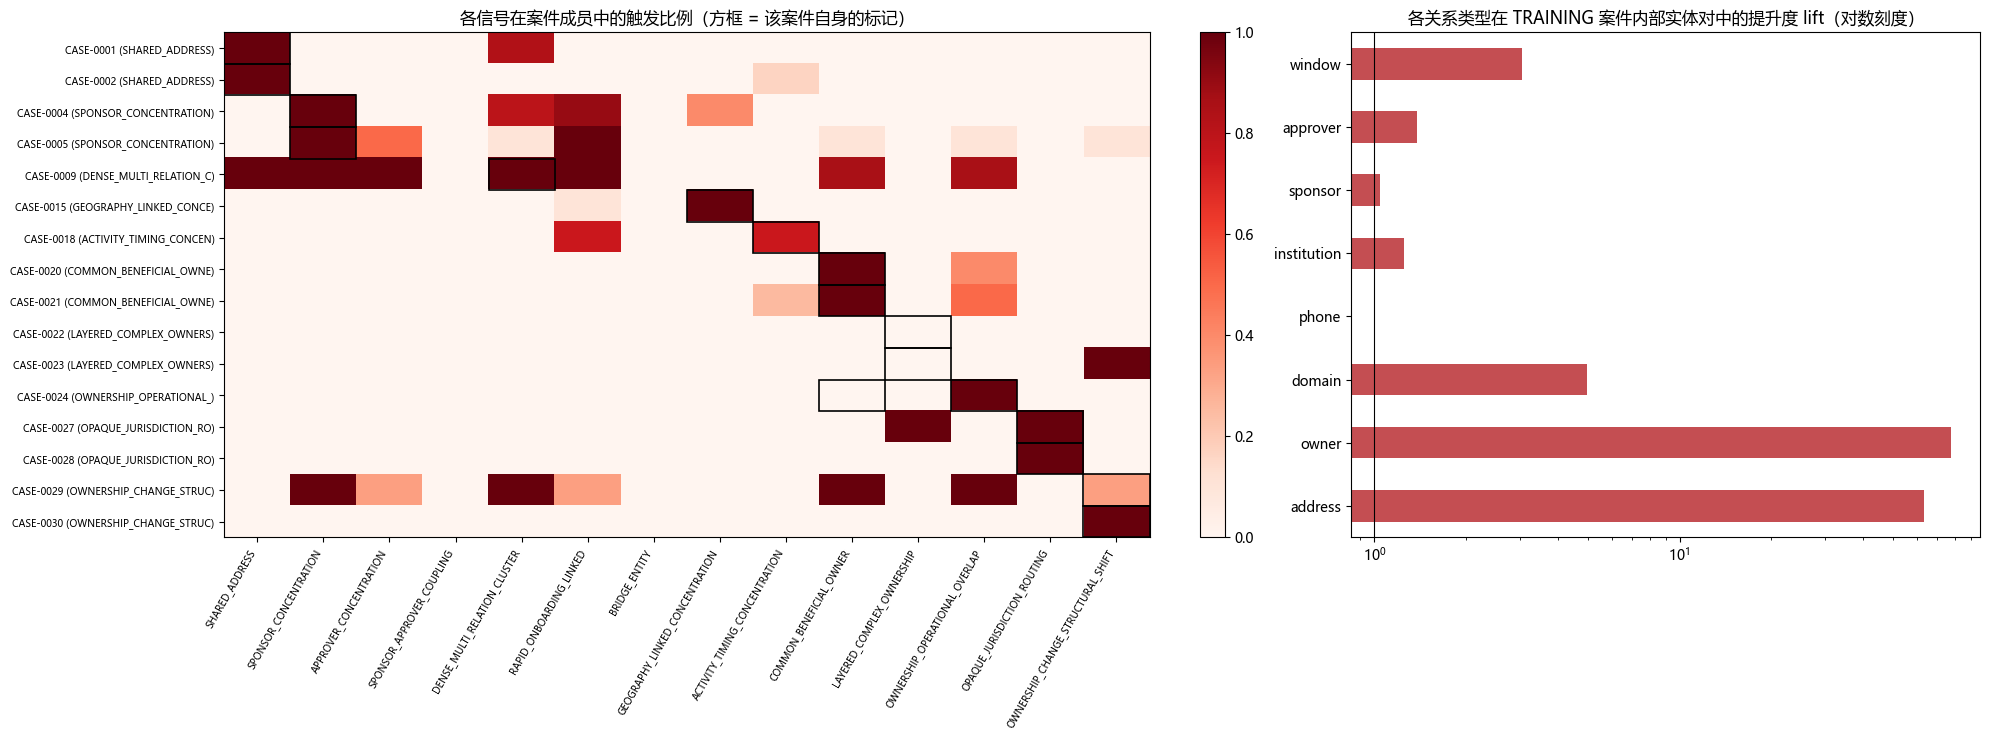

没有任何成员触发自身类型信号的案件： ['CASE-0022', 'CASE-0023']

2026-06-30 的候选模式（不使用标签；只显示训练案件）


,definition,vendors,训练案件成员数,14 个信号中最强值的中位数
candidate,,,,
PUBLIC_INSTITUTION_EXPERT_CLUSTER,同一公立机构中另有 ≥ 2 名专家，且由同一发起人（sponsor）聘用,6,0,0.64
FMV_CAP_BREACH,专家获得的付款超过现行年度公允市场价值（FMV）上限,3,0,0.00
PAYMENT_AFTER_TERMINATION,终止月份之后的月份仍有付款,1,0,0.00
SPLIT_ENGAGEMENTS,同一供应商与同一发起人在 28 天内有 ≥ 2 笔小额合作，合计超过第 1 档限额,4,0,0.17
UNDECLARED_SHARED_CONTACT,电话或自有邮箱域名与申报集团以外的实体共享,105,11,0.31
REONBOARDED_AFTER_TERMINATION,与此前已终止的记录有相同税号或电话,21,1,0.34
SELF_APPROVAL,发起人审批自己发起的合作,50,7,0.34


共享 >= 2 种关系的实体群组，按其解释来源分类（declared group = 已申报集团，14 typologies = 14 种类型，nothing = 无法解释）


components  entities  largest
explained_by   signature                                                           
nothing        approver+sponsor                               20        49        4
14 typologies  approver+sponsor                               19       383      127
               sponsor+window                                 12        40       10
               approver+window                                 4        10        4
nothing        sponsor+window                                  4         8        2
14 typologies  institution+sponsor                             3        17       10
               domain+owner                                    2         4        2
               address+approver                                1         7        7
               address+approver+owner+sponsor+window           1        13       13
               address+owner+sponsor                           1         3        3
               domain+sponsor                                  1        16       16
               domain+phone                                    1         3        3
               address+sponsor                                 1         5        5
               approver+owner+sponsor+window                   1         4        4
declared group address+domain                                  1         2        2

In [3]:
SIG14 = [f"s_{k}" for k in l2f.TYPOLOGIES]
TRAIN_CASES = CASES_IN["TRAINING"]
CUT_OF = {"TRAINING": T_TRAIN, "VALIDATION": T_VAL, "TEST": T_TEST}

# (1) 哪个类型信号在哪个训练案件的成员上触发（每个案件取其所属时期的截止日期）
heat = pd.DataFrame({c: (L2[CUT_OF[case_period[c]]].loc[list(case_mem[c]), SIG14] > 0).mean() for c in TRAIN_CASES}).T
heat.columns = [k.replace("s_", "") for k in heat.columns]
fig, axes = plt.subplots(1, 2, figsize=(20, 7.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
im = axes[0].imshow(heat.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(heat.columns)), heat.columns, rotation=60, ha="right", fontsize=7)
axes[0].set_yticks(range(len(heat)), [f"{c} ({case_typ[c].split('|')[0][:22]})" for c in heat.index], fontsize=7)
for i, c in enumerate(heat.index):
    for k in case_typ[c].split("|"):
        if k in heat.columns:
            axes[0].add_patch(plt.Rectangle((list(heat.columns).index(k) - 0.5, i - 0.5), 1, 1, fill=False, ec="k", lw=1.2))
axes[0].set_title("各信号在案件成员中的触发比例（方框 = 该案件自身的标记）")
plt.colorbar(im, ax=axes[0], fraction=0.03)

# (2) 连接指标：哪些关系类型把同一训练案件的成员连在一起（TR_TRAIN，2024-06-30）
re_of = CTX[T_TRAIN]["T"]["tp"].re
within = {tuple(sorted(p)) for c in CASES_IN["TRAINING"]
          for p in combinations(sorted(set(re_of.reindex(list(case_mem[c])).dropna())), 2)}
pairs_tr = CTX[T_TRAIN]["pairs"]
KINDS = ["address", "owner", "domain", "phone", "institution", "sponsor", "approver", "window"]
lift = {}
for kd in KINDS:
    w_ = np.mean([kd in k for p, k in pairs_tr.items() if p in within])
    o_ = np.mean([kd in k for p, k in pairs_tr.items() if p not in within])
    lift[kd] = w_ / o_ if o_ > 0 else np.nan
pd.Series(lift).plot.barh(ax=axes[1], color="#C44E52", logx=True)
axes[1].axvline(1, c="k", lw=0.8)
axes[1].set_title("各关系类型在 TRAINING 案件内部实体对中的提升度 lift（对数刻度）")
plt.tight_layout(); plt.savefig(f"{OUT}/L2_eda_zh.png", dpi=130); plt.show()
print("没有任何成员触发自身类型信号的案件：",
      [c for c in TRAIN_CASES if all(heat.loc[c].get(k, 0) == 0 for k in case_typ[c].split("|"))])

# (3) 14 种类型之外的模式：在最新截止日期上、不使用标签进行搜索
F_s, L1_s, T_s = L2[T_TEST], L1[T_TEST], CTX[T_TEST]["T"]
S14 = F_s[SIG14].max(axis=1)
train_member = members(TRAIN_CASES)
CANDIDATES = {
    "PUBLIC_INSTITUTION_EXPERT_CLUSTER": ("同一公立机构中另有 ≥ 2 名专家，且由同一发起人（sponsor）聘用",
                                          F_s.nx_inst_expert_cluster_public >= l2f.MIN_GROUP - 1),
    "FMV_CAP_BREACH": ("专家获得的付款超过现行年度公允市场价值（FMV）上限", L1_s.max_fmv_cap_ratio > 1),
    "PAYMENT_AFTER_TERMINATION": ("终止月份之后的月份仍有付款", L1_s.n_months_paid_after_term >= 1),
    "SPLIT_ENGAGEMENTS": ("同一供应商与同一发起人在 28 天内有 ≥ 2 笔小额合作，合计超过第 1 档限额",
                          F_s.nx_split_engagements >= 2),
    "UNDECLARED_SHARED_CONTACT": ("电话或自有邮箱域名与申报集团以外的实体共享",
                                  F_s.nx_contact_shared_undeclared >= 1),
    "REONBOARDED_AFTER_TERMINATION": ("与此前已终止的记录有相同税号或电话", F_s.nx_reonboarded_after_termination >= 1),
    "SELF_APPROVAL": ("发起人审批自己发起的合作", L1_s.n_approver_is_sponsor >= 1),
}
cand = pd.DataFrame([dict(candidate=n, definition=d, vendors=int(m.sum()),
                          **{"训练案件成员数": int(sum(r in train_member for r in m[m].index)),
                             "14 个信号中最强值的中位数": round(float(S14[m].median()), 2) if m.any() else np.nan})
                     for n, (d, m) in CANDIDATES.items()]).set_index("candidate")
print("\n2026-06-30 的候选模式（不使用标签；只显示训练案件）")
display(cand)

# 残余结构：共享 >= 2 种关系、且没有任何类型信号能解释的实体群组
pairs_s, tp_s = CTX[T_TEST]["pairs"], T_s["tp"]
G2 = nx.Graph([p for p, k in pairs_s.items() if len(k) >= 2])
s_re = S14.groupby(tp_s.re).max()
res_rows = []
for comp in nx.connected_components(G2):
    kinds = pd.Series(["+".join(sorted(pairs_s[tuple(sorted(e))])) for e in G2.subgraph(comp).edges]).value_counts()
    recs = tp_s.index[tp_s.re.isin(comp)]
    grp = tp_s.loc[recs].group
    res_rows.append(dict(size=len(comp), signature=kinds.index[0], max_s14=float(s_re.reindex(list(comp)).max()),
                         explained_by="declared group" if grp.notna().all() and grp.nunique() == 1
                         else ("14 typologies" if s_re.reindex(list(comp)).max() >= 0.3 else "nothing")))
resid = pd.DataFrame(res_rows).groupby(["explained_by", "signature"]).agg(components=("size", "size"),
                                                                         entities=("size", "sum"), largest=("size", "max"))
print("共享 >= 2 种关系的实体群组，按其解释来源分类（declared group = 已申报集团，14 typologies = 14 种类型，nothing = 无法解释）")
display(resid.sort_values("components", ascending=False).head(15))

下一格逐一查看每个候选模式涉及的具体记录，作为第 3 节判断"是否成为新类型"的证据。

In [4]:
inst_ = pd.read_csv(os.path.join(DATA_DIR, "healthcare_institutions.csv")).set_index("institution_id")
pay_m = T_s["pay"].assign(m=lambda d: d.month.dt.to_period("M")).groupby(["record_id", "m"]).amount_usd.sum().unstack().fillna(0)

ids = CANDIDATES["PUBLIC_INSTITUTION_EXPERT_CLUSTER"][1]
ids = ids[ids].index
aff_ = T_s["inst"][T_s["inst"].record_id.isin(ids) & (T_s["inst"].link_type == "AFFILIATED_WITH")]
detail = aff_.merge(T_s["tp"][["expert_type", "onboarding_date"]], left_on="record_id", right_index=True)
detail = detail.join(inst_[["inst_type", "country", "public_sector"]], on="institution")
detail["sponsors"] = detail.record_id.map(T_s["eng"].dropna(subset=["sponsor"]).groupby("record_id").sponsor.agg(
    lambda s: "|".join(sorted(set(s)))))
detail["peak_month"] = detail.record_id.map(pay_m.idxmax(axis=1).astype(str))
detail["peak / median month"] = detail.record_id.map((pay_m.max(axis=1) / pay_m.replace(0, np.nan).median(axis=1)).round(1))
print("PUBLIC_INSTITUTION_EXPERT_CLUSTER")
display(detail[["record_id", "institution", "inst_type", "country", "public_sector", "expert_type", "onboarding_date",
                "sponsors", "peak_month", "peak / median month"]])

ids = CANDIDATES["FMV_CAP_BREACH"][1]
print("FMV_CAP_BREACH")
display(L1_s.loc[ids[ids].index, ["max_fmv_cap_ratio", "n_pay_months"]].join(T_s["tp"][["expert_type", "country", "onboarding_date"]]))

ids = CANDIDATES["PAYMENT_AFTER_TERMINATION"][1]
print("PAYMENT_AFTER_TERMINATION")
display(L1_s.loc[ids[ids].index, ["n_months_paid_after_term"]].join(
    T_s["tp"][["party_type", "country", "onboarding_date", "terminated_date"]]))

ids = CANDIDATES["SPLIT_ENGAGEMENTS"][1]
print("SPLIT_ENGAGEMENTS")
display(F_s.loc[ids[ids].index, ["nx_split_engagements"]].join(T_s["tp"][["party_type", "country"]]))

contact = T_s["contact"].assign(re=lambda d: d.record_id.map(T_s["tp"].re))
shared = contact[contact.record_id.isin(CANDIDATES["UNDECLARED_SHARED_CONTACT"][1].pipe(lambda m: m[m].index))]
names = T_s["tp"].legal_name
matcher = gb.NameMatcher([gb.name_tokens(n) for n in names])
sim = [l2f.name_similarity(matcher, names[a], names[b])
       for v, d in shared.groupby("value") for a, b in combinations(sorted(d.record_id), 2)]
print(f"UNDECLARED_SHARED_CONTACT：共享电话/域名的供应商对之间的名称相似度："
      f"中位数 {np.median(sim):.2f}，≥ {l2f.NAME_SIM} 的比例：{np.mean(np.array(sim) >= l2f.NAME_SIM):.0%}")

ap_ = pd.read_csv(os.path.join(DATA_DIR, "tp_engagement_approvals.csv")).merge(
    pd.read_csv(os.path.join(DATA_DIR, "tp_engagements.csv"))[["engagement_id", "sponsor_employee_id"]], on="engagement_id")
self_ = ap_[(ap_.approval_type == "financial") & (ap_.approver_employee_id == ap_.sponsor_employee_id)]
roles_ = pd.read_csv(os.path.join(DATA_DIR, "employee_roles.csv")).drop_duplicates("employee_id").set_index("employee_id").role
print("SELF_APPROVAL：审批自己发起合作的员工岗位：",
      self_.approver_employee_id.map(roles_).value_counts().to_dict())

PUBLIC_INSTITUTION_EXPERT_CLUSTER


,record_id,institution,inst_type,country,public_sector,expert_type,onboarding_date,sponsors,peak_month,peak / median month
5506,TP-95184614,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-06-21,EMP-87A0ECFB,2026-04,2.2
9346,TP-2A796C56,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-03-26,EMP-87A0ECFB,2026-04,5.2
11029,TP-BCC685BD,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-02-09,EMP-87A0ECFB,2026-04,6.1
17669,TP-3967C884,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-05-22,EMP-87A0ECFB,2026-04,3.0
18994,TP-C6CDBD3A,HCO-9920B679,hospital,VN,True,hcp_consultant,2024-12-29,EMP-87A0ECFB,2026-04,4.9
19068,TP-7A4B5571,HCO-9920B679,hospital,VN,True,hcp_consultant,2025-08-28,EMP-87A0ECFB,2026-04,5.7


FMV_CAP_BREACH


,max_fmv_cap_ratio,n_pay_months,expert_type,country,onboarding_date
record_id,,,,,
TP-7CB3B5CE,2.776162,24.0,investigator_kol,TW,2010-03-02
TP-2AD5101E,1.241995,33.0,investigator_kol,CA,2023-10-13
TP-60212374,1.155575,26.0,investigator_kol,US,2023-12-12


PAYMENT_AFTER_TERMINATION


,n_months_paid_after_term,party_type,country,onboarding_date,terminated_date
record_id,,,,,
TP-33FC40CA,1.0,organization,DE,2020-07-20,2025-01-25


SPLIT_ENGAGEMENTS


,nx_split_engagements,party_type,country
record_id,,,
TP-82B3D29F,2.0,organization,DE
TP-744FAEAE,2.0,organization,JP
TP-5FFCFBAD,2.0,organization,US
TP-8350BEF1,2.0,organization,MA


UNDECLARED_SHARED_CONTACT：共享电话/域名的供应商对之间的名称相似度：中位数 0.00，≥ 0.7 的比例：9%
SELF_APPROVAL：审批自己发起合作的员工岗位： {'market_gm': 56}


## 3. 新类型

**EDA 显示了什么。**
- **14 个检测器都能在各自对应的案件上触发。** 热力图几乎每一行都有一个深色方框：TRAINING 案件的成员会触发其自身标记对应的信号。例外是 CASE-0022 和 CASE-0023，它们是只有一个供应商的分层所有权案件，在 2024-06-30 时所有权链还没达到 `DEPTH_MIN`。
- **把案件成员连在一起的是共享的罕见关系，而不是共享的员工。** 同一 TRAINING 案件内部的实体对，共享地址或所有人的频率远高于其他实体对（lift 分别为 63 和 78）。发起人和审批人关联在案件内外几乎一样常见（lift 1.0 和 1.4）；入驻时间窗口介于两者之间（3.0）。

**14 种类型之外的候选模式**（在 2026-06-30 不使用标签搜索，细节见上一格）：

| 候选 | 证据 | 决定 |
|---|---|---|
| **PUBLIC_INSTITUTION_EXPERT_CLUSTER**（公立机构专家群）：同一公立机构中 ≥ 3 名个人专家，由同一发起人聘用 | 越南（VN）一家公立医院的 6 名 HCP（医疗专业人士）顾问，同一个发起人，8 个月内全部入驻，付款高峰都在 2026-04（是各自月度中位数的 2–6 倍）。没有地址、所有人、电话或域名把他们连起来，只有机构和发起人。这正是文档里的"员工 → 公立机构 → HCP"结构（§3.1）。 | **新类型** |
| **FMV_CAP_BREACH**（超过公允市场价值上限）：专家获得的付款超过现行年度公允市场价值上限 | 3 名研究者（TW、CA、US），付款是上限的 1.16–2.78 倍。不需要任何关系，14 个信号也都没有在他们身上触发（最强信号的中位数为 0.00）。文档把这类单条记录的发现视为"与关系类型分开打分"（§4）。 | **新类型**（记录层面） |
| **PAYMENT_AFTER_TERMINATION**（终止后付款）：终止日期之后仍继续付款 | 1 个供应商（DE），2025-01 终止，之后某个月仍有付款。这是单条记录上的控制失效，没有任何时间或其他信号在它上面触发。 | **新类型** |
| SPLIT_ENGAGEMENTS（拆分合作） | 4 个供应商，没有 TRAINING 案件成员 | 太少，无法和正常的重复签约区分开；不作为类型 |
| UNDECLARED_SHARED_CONTACT（未申报的共享联系方式） | 105 个供应商；其中 11 个是 TRAINING 案件成员，大约就是基础比例（797 个里有 70 个） | 很常见，而且在案件中没有富集；适合当作图里的边，而不是一种类型 |
| REONBOARDED_AFTER_TERMINATION（终止后重新入驻） | 21 个供应商，1 个 TRAINING 案件成员 | 大多是通过共享电话关联到的同一批记录；不作为类型 |
| SELF_APPROVAL（自我审批） | 50 个供应商；全部 56 次自我审批都来自 `market_gm` | 由岗位设计造成，是看起来像但其实无害的情形；不作为类型 |

**残余结构。** 共享 ≥ 2 种关系、而且没有任何类型能解释的实体群组都很小（≤ 4 个实体）。它们的特征是 `approver+sponsor` 或 `sponsor+window`：同一个员工发起、另一个员工审批同样几个供应商，这是正常的审批路由。所以不再提出新的类型。

三个新类型也有了自己的变量和信号，使用与 14 种类型相同的罕见度变换（`layer2_features.NEW_GROUPS`）。接下来，对全部 17 种类型用同样的方法做检验。

**加入增益与去除损失（下一格）。** 全部只在 `TR_TRAIN` 上计算，使用分组 5 折 CV × 3 个随机种子 × RF 和 GB，也就是每种类型有 30 个 `AP_case` 配对差值。
- **加入增益（add gain）** = (Layer 1 + 该类型) − (Layer 1)：这个类型单独加进去有没有用？
- **去除损失（drop loss）** = (Layer 1 + 全部 17 种) − (Layer 1 + 除它以外的全部 17 种)：在已有其他类型的情况下，它是否不可替代？
- 只要任一值超过一个标准误（SE），这个类型就被**采用**。这是"一倍标准误规则"（Hastie 等，*ESL* §7.10）；文档在 §1（"每种关系类型的价值"）和 §9.2（"消融关系类型"）中要求做这类比较。


In [5]:
for t_ in CUTOFFS:
    L2[t_] = L2[t_].join(l2f.new_signals(L2[t_], L1[t_]))
ALL_GROUPS = GROUPS | l2f.NEW_GROUPS
MODEL_FN = {"RF": "4_random_forest", "GB": "5_gradient_boosting"}


def frame(t_, rids, cols):
    X = L1[t_].join(L2[t_].drop(columns=[c for c in L2[t_].columns if c in L1[t_].columns]))
    return X.loc[rids, list(dict.fromkeys(cols))].values.astype(float)


def _fit(model, Xtr, ytr, gtr, Xte, seed):
    import warnings
    warnings.filterwarnings("ignore")
    return l1.get_score(l1.fit_model(MODEL_FN[model], Xtr, ytr, gtr, seed), Xte)


def add_drop(TR, step, seeds=(0, 1, 2), n_folds=5):
    """把每个类型组加入 Layer 1 带来的增益，以及从“Layer 1 + 全部组”中去掉它造成的损失（AP_case，交叉验证）。
    `step` 只用于选取 Layer 1 在 TR_TRAIN 上拟合时保存的变量选择结果。"""
    jobs, meta = [], []
    for seed in seeds:
        base = L1_SEL[(seed, step, -1)]
        every = [v for g in ALL_GROUPS.values() for v in g]
        variants = {"base": base, "full": base + every}
        for k, vs in ALL_GROUPS.items():
            variants[f"add|{k}"] = base + vs
            variants[f"drop|{k}"] = base + [v for v in every if v not in vs]
        folds = list(StratifiedGroupKFold(n_folds, shuffle=True, random_state=2000 + seed).split(TR["rid"], TR["y"], TR["g"]))
        for name, cols in variants.items():
            X = frame(TR["t"], TR["rid"], cols)
            for f_, (tr, te) in enumerate(folds):
                for model in MODEL_FN:
                    jobs.append(delayed(_fit)(model, X[tr], TR["y"][tr], TR["g"][tr], X[te], seed))
                    meta.append((seed, f_, model, name, te))
    out = Parallel(n_jobs=N_JOBS)(jobs)
    r = pd.DataFrame([dict(seed=s, fold=f, model=m, variant=n,
                           AP_case=average_precision_score(TR["y"][te], sc, sample_weight=TR["w"][te]))
                      for (s, f, m, n, te), sc in zip(meta, out)]).set_index(["seed", "fold", "model", "variant"]).AP_case.unstack()
    rows = []
    for k in ALL_GROUPS:
        gain, loss = r[f"add|{k}"] - r["base"], r["full"] - r[f"drop|{k}"]
        se_g, se_l = gain.std(ddof=1) / np.sqrt(len(gain)), loss.std(ddof=1) / np.sqrt(len(loss))
        rows.append({"typology": k, "given / new": "new" if k in l2f.NEW_GROUPS else "given",
                     "training cases with tag": sum(k in case_typ[c].split("|") for c in TR["cases"]),
                     "add gain": round(gain.mean(), 3), "add SE": round(se_g, 3), "add gain > 1 SE": gain.mean() > se_g,
                     "drop loss": round(loss.mean(), 3), "drop SE": round(se_l, 3), "drop loss > 1 SE": loss.mean() > se_l})
    t = pd.DataFrame(rows).set_index("typology")
    t["selected"] = t["add gain > 1 SE"] | t["drop loss > 1 SE"]
    return t, r[["base", "full"]].mean()


t0 = time.time()
ADD_DROP, ref_ = add_drop(TR_TRAIN, "VALIDATION")
print(f"TR_TRAIN：AP_case Layer 1 = {ref_['base']:.3f}，Layer 1 + 全部 17 组 = {ref_['full']:.3f} "
      f"（5 折 CV × 3 个随机种子 × RF/GB = 30 个配对差值）；用时 {(time.time() - t0) / 60:.1f} 分钟")
display(ADD_DROP)
ADD_DROP.to_csv(f"{OUT}/L2_add_drop.csv")

TR_TRAIN：AP_case Layer 1 = 0.357，Layer 1 + 全部 17 组 = 0.660 （5 折 CV × 3 个随机种子 × RF/GB = 30 个配对差值）；用时 3.0 分钟


,given / new,training cases with tag,add gain,add SE,add gain > 1 SE,drop loss,drop SE,drop loss > 1 SE,selected
typology,,,,,,,,,
SHARED_ADDRESS,given,2,-0.034,0.014,False,0.027,0.008,True,True
SPONSOR_CONCENTRATION,given,2,0.162,0.034,True,0.081,0.019,True,True
APPROVER_CONCENTRATION,given,0,-0.022,0.016,False,-0.011,0.007,False,False
SPONSOR_APPROVER_COUPLING,given,0,0.009,0.014,False,-0.005,0.006,False,False
DENSE_MULTI_RELATION_CLUSTER,given,1,0.155,0.032,True,-0.026,0.017,False,True
RAPID_ONBOARDING_LINKED,given,0,0.153,0.027,True,-0.003,0.011,False,True
BRIDGE_ENTITY,given,0,0.018,0.007,True,0.011,0.008,True,True
GEOGRAPHY_LINKED_CONCENTRATION,given,1,-0.001,0.012,False,0.013,0.010,True,True
ACTIVITY_TIMING_CONCENTRATION,given,1,-0.018,0.011,False,-0.003,0.005,False,False


**根据上一格的结果**，保留被采用（`selected`）的类型，列出最终进入模型的 Layer 2 变量（既有类型 + 新类型）。

In [6]:
sel = ADD_DROP.index[ADD_DROP.selected]
L2_GIVEN_VARS = [v for k in sel if k in GROUPS for v in GROUPS[k]]
L2_NEW_VARS = [v for k in sel if k in l2f.NEW_GROUPS for v in l2f.NEW_GROUPS[k]]
names = pd.DataFrame([dict(variable=v, typology=k, **{"given / new": "new" if k in l2f.NEW_GROUPS else "given"})
                      for k in sel for v in ALL_GROUPS[k]]).set_index("variable")
names.to_csv(f"{FZ2}/layer2_variables.csv")
print(f"Layer 2 变量：{len(L2_GIVEN_VARS)} 个既有类型变量 + {len(L2_NEW_VARS)} 个新类型变量")
print("既有：", ", ".join(L2_GIVEN_VARS) or "—")
print("新增：", ", ".join(L2_NEW_VARS) or "—")
display(names)

Layer 2 变量：59 个既有类型变量 + 2 个新类型变量
既有： sa_n_cohabitants, sa_n_cohab_undeclared, sa_benign_hub, lk_aa_address_max, sa_overlap_days, sa_cohab_shared_sponsor, s_SHARED_ADDRESS, sc_max_portfolio, sc_burst, sc_burst_peer_z, lk_aa_sponsor_max, sc_portfolio_hhi, sc_portfolio_entropy, s_SPONSOR_CONCENTRATION, dc_max_shared_types, dc_n_partners_3types, dc_component_size, lk_jaccard_max, lk_adamic_adar_max, lk_adamic_adar_sum, lk_aa_phone_max, lk_aa_domain_max, dc_kind_entropy, s_DENSE_MULTI_RELATION_CLUSTER, ro_n_linked_in_window, ro_country_prior_rate, ro_burst_ratio, ro_event_explained, ro_min_interarrival_days, ro_country_burstiness, s_RAPID_ONBOARDING_LINKED, br_n_communities, br_n_inst_countries, br_public_share, lk_aa_institution_max, br_participation, s_BRIDGE_ENTITY, gc_new_intermediaries_12m, gc_existing_intermediaries, gc_new_ratio, gc_top_sponsor_share, gc_owner_domicile_differs, s_GEOGRAPHY_LINKED_CONCENTRATION, co_n_coowned, co_n_coowned_undeclared, co_n_coowned_dissimilar, lk_aa_own

,typology,given / new
variable,,
sa_n_cohabitants,SHARED_ADDRESS,given
sa_n_cohab_undeclared,SHARED_ADDRESS,given
sa_benign_hub,SHARED_ADDRESS,given
lk_aa_address_max,SHARED_ADDRESS,given
sa_overlap_days,SHARED_ADDRESS,given
...,...,...
oo_n_owner_partners_ops_overlap,OWNERSHIP_OPERATIONAL_OVERLAP,given
oo_expert_owns_agency_same_sponsor,OWNERSHIP_OPERATIONAL_OVERLAP,given
s_OWNERSHIP_OPERATIONAL_OVERLAP,OWNERSHIP_OPERATIONAL_OVERLAP,given


## 4. 模型与风险分

共比较 7 个模型，全部只在 TRAINING 上训练一次：

| 模型 | 说明 |
|---|---|
| L1 RF / L1 GB | Layer 1 的基线模型，直接读取 Layer 1 保存的分数 |
| L2 RF / L2 GB | Layer 1 选中的变量 + 被采用的既有类型的 Layer 2 变量 |
| L2 RF + new / L2 GB + new | 再加上新类型的变量 |
| L2 risk score | 不训练机器学习模型，只把 17 个类型信号按权重合成一个分数 |

`risk_score_table` 会显示每个模型在 TEST 上排名前 15 的记录：风险分（0–100 百分位）、模型原始分数、最强的类型信号、它属于哪个真实案件，以及它在前 100 名中被组进了哪个预测案件（P1、P2……，括号里是该预测案件的 vendor 数）。

In [7]:
from layer1_models import make_model, fit_model, get_score       # Layer 1 的 RF 与 GB 函数

RUNS = {}
for m, name in [("4_random_forest", "L1 RF"), ("5_gradient_boosting", "L1 GB")]:
    RUNS[name] = []
    for (p, seed), d in L1_OOF.groupby(["period", "seed"]):
        assert (d.record_id.to_numpy() == EVAL_SET[p]["rid"]).all()
        RUNS[name].append((p, seed, d[f"score_{m}"].to_numpy()))
print("Layer 1 RF 与 GB：直接读取 Layer 1 notebook 固定保存的样本外分数（相同函数、相同折、相同随机种子）")


# ---- 从排好序的 vendor 到预测案件 ----
RARE_KINDS = {"address", "owner", "phone", "domain", "institution"}   # 罕见关系
# 一种关系只有在它承载了两个 vendor 都触发的某种类型时才相连（文档 §2），或者两者共享 >= 2 种罕见关系；
# 单独一个共享值（一个机构、一个审批人）不会把不相关的 vendor 并在一起
TYP_KINDS = {"SHARED_ADDRESS": {"address"}, "SPONSOR_CONCENTRATION": {"sponsor"}, "APPROVER_CONCENTRATION": {"approver"},
             "SPONSOR_APPROVER_COUPLING": {"sponsor", "approver"},
             "DENSE_MULTI_RELATION_CLUSTER": RARE_KINDS | {"sponsor", "approver", "window"}, "RAPID_ONBOARDING_LINKED": {"window"},
             "BRIDGE_ENTITY": {"institution"}, "GEOGRAPHY_LINKED_CONCENTRATION": {"sponsor"},
             "ACTIVITY_TIMING_CONCENTRATION": {"sponsor"}, "COMMON_BENEFICIAL_OWNER": {"owner"},
             "LAYERED_COMPLEX_OWNERSHIP": {"owner"}, "OWNERSHIP_OPERATIONAL_OVERLAP": {"owner", "sponsor"},
             "OPAQUE_JURISDICTION_ROUTING": {"owner"}, "OWNERSHIP_CHANGE_STRUCTURAL_SHIFT": {"owner"},
             "PUBLIC_INSTITUTION_EXPERT_CLUSTER": {"institution", "sponsor"}}
FIRE_MIN = 0.3        # 信号 >= 0.3 即认为该类型在这个 vendor 上"触发"（与第 3 节一致）
IOU_MIN = 0.5


def predicted_cases(t_, top_rids):
    """把前 k 名记录组成预测案件。两条记录属于同一解析实体、共享一种承载了双方都触发的类型的关系，或共享 >= 2 种罕见关系时相连。
    每个连通的组再用 Louvain 社区发现切分（边权 = 共享关系的种类数），避免一条弱边把两个案件串在一起。
    与谁都不相连的记录自成一个单 vendor 案件。按组内最靠前的排名排序。"""
    re_of, pairs = CTX[t_]["T"]["tp"].re, CTX[t_]["pairs"]
    sig = [c for c in SIG14 + [f"s_{k}" for k in l2f.NEW_TYPOLOGIES] if c in L2[t_].columns]
    top_rids = list(top_rids)
    by_re = defaultdict(list)
    for r in top_rids:
        e = re_of.get(r)
        by_re[r if pd.isna(e) else e].append(r)
    fired = {e: {c[2:] for c in sig if L2[t_].loc[rs, c].max() >= FIRE_MIN} for e, rs in by_re.items()}
    G = nx.Graph()
    G.add_nodes_from(top_rids)
    for rs in by_re.values():
        G.add_edges_from(zip(rs[:-1], rs[1:]), weight=10)
    for a, b in combinations(sorted(by_re), 2):
        k = pairs.get((a, b), set())
        if any(k & TYP_KINDS.get(t, set()) for t in fired[a] & fired[b]) or len(k & RARE_KINDS) >= 2:
            G.add_edge(by_re[a][0], by_re[b][0], weight=len(k))
    groups = []
    for comp in nx.connected_components(G):
        groups += ([set(c) for c in nx.community.louvain_communities(G.subgraph(comp), weight="weight", seed=0)]
                   if len(comp) > 2 else [set(comp)])
    pos = {r: i for i, r in enumerate(top_rids)}
    return sorted(groups, key=lambda g: min(pos[r] for r in g))


def iou(a, b):
    return len(a & b) / len(a | b)


def case_iou(members_, groups):
    """真实案件与任一预测案件之间的最大 IoU"""
    return max((iou(members_, g) for g in groups), default=0.0)

# ---- case 层面的审查队列：risk vendors -> 候选 case -> 所有 vendor 模型共用一个 case score ----
N_CAND = 150                     # 每个模型、每个时期取前 N_CAND 个 risk vendor 来组成候选 case
SIG17 = SIG14 + [f"s_{k}" for k in l2f.NEW_TYPOLOGIES]
RISK_V, CAND = {}, {}


def avg_score(name, period):
    ev = EVAL_SET[period]
    return pd.Series(np.mean([sc for p, seed, sc in RUNS[name] if p == period], axis=0), index=ev["rid"])


def risk_vendors(name, period="TEST", show=15):
    """模型分数最高的 N_CAND 个 vendor（各随机种子平均分），每个时期都保存"""
    for p in EVAL_SET:
        s_ = avg_score(name, p)
        top = s_.sort_values(ascending=False).head(N_CAND)
        sig = L2[EVAL_SET[p]["t"]].loc[top.index, SIG17]
        RISK_V.setdefault(name, {})[p] = pd.DataFrame({
            "排名": range(1, len(top) + 1), "模型分数": top.round(3),
            "百分位": s_.rank(pct=True).reindex(top.index).round(3),
            "最强类型信号": sig.idxmax(axis=1).str[2:].where(sig.max(axis=1) > 0, "—")})
    print(f"{name}：每个时期前 {N_CAND} 个 risk vendor；{period} 的前 {show} 个：")
    display(RISK_V[name][period].head(show))


def case_features(t_, g, pct):
    g = list(g)
    re_of, pairs = CTX[t_]["T"]["tp"].re, CTX[t_]["pairs"]
    ents = sorted({r if pd.isna(re_of.get(r)) else re_of.get(r) for r in g})
    kinds = [pairs.get((a, b), set()) for a, b in combinations(ents, 2)]
    share = (L2[t_].loc[g, SIG17] >= FIRE_MIN).mean()
    return dict(size=len(g), mean_pct=pct[g].mean(), max_pct=pct[g].max(),
                density=np.mean([bool(k) for k in kinds]) if kinds else 0.0,
                shared_typology=share.max() if len(g) > 1 else 0.0,
                typology=share.idxmax()[2:] if share.max() > 0 else "—", n_typologies=int((share > 0).sum()))


def candidate_cases(name, period="TEST", show=10):
    """把模型的 risk vendors 组成候选 case（predicted_cases），并计算 case score 要用的特征"""
    for p, rv in RISK_V[name].items():
        t_ = EVAL_SET[p]["t"]
        pct = avg_score(name, p).rank(pct=True)
        CAND.setdefault(name, {})[p] = pd.DataFrame(
            [dict(members=frozenset(g), **case_features(t_, g, pct)) for g in predicted_cases(t_, rv.index)])
    d = CAND[name][period]
    print(f"{name}：{N_CAND} 个 risk vendor -> {len(d)} 个候选 case（{period}），其中 {int((d['size'] > 1).sum())} 个有 >= 2 个 vendor；"
          f"按成员平均分排前 {show} 个：")
    display(d.sort_values("mean_pct", ascending=False).head(show)
            .assign(members=lambda x: x.members.map(lambda m: ", ".join(sorted(m)))).round(3))


def risk_score_table(name, period="TEST", k=15):
    """模型的风险分：对各随机种子的分数取平均，再换算成该时期内 0–100 的百分位；返回前 k 条记录"""
    ev = EVAL_SET[period]
    s_ = np.mean([sc for p, seed, sc in RUNS[name] if p == period], axis=0)
    rs = pd.Series(s_, index=ev["rid"]).rank(pct=True).mul(100).round(1)
    case_of = {r: c for c in ev["cases"] for r in case_mem[c]}
    ranked = rs.sort_values(ascending=False)
    top = ranked.head(k).to_frame("风险分")
    top["模型分数"] = pd.Series(s_, index=ev["rid"]).reindex(top.index).round(3)
    top["最强类型信号"] = L2[ev["t"]].loc[top.index, SIG14].idxmax(axis=1).str[2:].where(
        L2[ev["t"]].loc[top.index, SIG14].max(axis=1) > 0, "—")
    top["案件"] = top.index.map(case_of).fillna("—")
    groups = predicted_cases(ev["t"], ranked.head(100).index)
    group_of = {r: j for j, g in enumerate(groups) for r in g}
    top["预测案件（前 100 名）"] = [f"P{group_of[r] + 1} ({len(groups[group_of[r]])} vendors)" for r in top.index]
    top.insert(0, "排名", range(1, len(top) + 1))
    found = [c for c in ev["cases"] if case_iou(case_mem[c], groups) > IOU_MIN]
    print(f"{name} — {period}：共 {len(rs)} 条记录中的前 {k} 名；前 100 名组成 {len(groups)} 个预测案件；"
          f"与预测案件 IoU > {IOU_MIN} 的真实案件："
          f"{len(found)}/{len(ev['cases'])}")
    display(top)

Layer 1 RF 与 GB：直接读取 Layer 1 notebook 固定保存的样本外分数（相同函数、相同折、相同随机种子）


In [8]:
risk_score_table("L1 RF")

L1 RF — TEST：共 909 条记录中的前 15 名；前 100 名组成 71 个预测案件；与预测案件 IoU > 0.5 的真实案件：4/10


,排名,风险分,模型分数,最强类型信号,案件,预测案件（前 100 名）
TP-F36DC60F,1,99.9,0.948,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-BAB9A564,2,99.9,0.948,—,—,P2 (1 vendors)
TP-B19D89EE,3,99.8,0.908,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-3DF71B2C,4,99.7,0.905,—,—,P3 (1 vendors)
TP-9E9DFA14,5,99.6,0.894,—,—,P4 (1 vendors)
TP-74BB7339,6,99.4,0.894,APPROVER_CONCENTRATION,—,P5 (1 vendors)
TP-ABC566F2,7,99.3,0.891,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P6 (3 vendors)
TP-E5EAE75E,8,99.2,0.881,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P6 (3 vendors)
TP-9184B950,9,99.2,0.881,—,—,P7 (1 vendors)
TP-E62F69EE,10,99.0,0.875,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P6 (3 vendors)


In [9]:
risk_vendors("L1 RF")

L1 RF：每个时期前 150 个 risk vendor；TEST 的前 15 个：


,排名,模型分数,百分位,最强类型信号
TP-F36DC60F,1,0.948,0.999,RAPID_ONBOARDING_LINKED
TP-BAB9A564,2,0.948,0.999,—
TP-B19D89EE,3,0.908,0.998,RAPID_ONBOARDING_LINKED
TP-3DF71B2C,4,0.905,0.997,—
TP-9E9DFA14,5,0.894,0.996,—
TP-74BB7339,6,0.894,0.994,APPROVER_CONCENTRATION
TP-ABC566F2,7,0.891,0.993,DENSE_MULTI_RELATION_CLUSTER
TP-E5EAE75E,8,0.881,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-9184B950,9,0.881,0.992,—
TP-E62F69EE,10,0.875,0.990,DENSE_MULTI_RELATION_CLUSTER


In [10]:
candidate_cases("L1 RF")

L1 RF：150 个 risk vendor -> 115 个候选 case（TEST），其中 11 个有 >= 2 个 vendor；按成员平均分排前 10 个：


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
1,TP-BAB9A564,1,0.999,0.999,0.0,0.0,—,0
0,"TP-B19D89EE, TP-F36DC60F",2,0.999,0.999,1.0,1.0,RAPID_ONBOARDING_LINKED,4
2,TP-3DF71B2C,1,0.997,0.997,0.0,0.0,—,0
3,TP-9E9DFA14,1,0.996,0.996,0.0,0.0,—,0
4,TP-74BB7339,1,0.994,0.994,0.0,0.0,—,0
5,"TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",3,0.992,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,5
6,TP-9184B950,1,0.992,0.992,0.0,0.0,—,0
7,TP-9A788A61,1,0.989,0.989,0.0,0.0,—,0
8,TP-BEBF4712,1,0.988,0.988,0.0,0.0,—,0
9,TP-92E3F328,1,0.987,0.987,0.0,0.0,—,0


In [11]:
risk_score_table("L1 GB")

L1 GB — TEST：共 909 条记录中的前 15 名；前 100 名组成 84 个预测案件；与预测案件 IoU > 0.5 的真实案件：3/10


,排名,风险分,模型分数,最强类型信号,案件,预测案件（前 100 名）
TP-F36DC60F,1,99.9,0.967,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-BAB9A564,2,99.9,0.967,—,—,P2 (1 vendors)
TP-B19D89EE,3,99.8,0.944,RAPID_ONBOARDING_LINKED,—,P1 (2 vendors)
TP-BEBF4712,4,99.7,0.937,—,—,P3 (1 vendors)
TP-74BB7339,5,99.6,0.933,APPROVER_CONCENTRATION,—,P4 (1 vendors)
TP-3DF71B2C,6,99.4,0.927,—,—,P5 (1 vendors)
TP-92E3F328,7,99.3,0.923,—,—,P6 (1 vendors)
TP-27CA3848,8,99.2,0.897,—,—,P7 (1 vendors)
TP-9E9DFA14,9,99.1,0.895,—,—,P8 (1 vendors)
TP-ABC566F2,10,99.0,0.893,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P9 (3 vendors)


In [12]:
risk_vendors("L1 GB")

L1 GB：每个时期前 150 个 risk vendor；TEST 的前 15 个：


,排名,模型分数,百分位,最强类型信号
TP-F36DC60F,1,0.967,0.999,RAPID_ONBOARDING_LINKED
TP-BAB9A564,2,0.967,0.999,—
TP-B19D89EE,3,0.944,0.998,RAPID_ONBOARDING_LINKED
TP-BEBF4712,4,0.937,0.997,—
TP-74BB7339,5,0.933,0.996,APPROVER_CONCENTRATION
TP-3DF71B2C,6,0.927,0.994,—
TP-92E3F328,7,0.923,0.993,—
TP-27CA3848,8,0.897,0.992,—
TP-9E9DFA14,9,0.895,0.991,—
TP-ABC566F2,10,0.893,0.990,DENSE_MULTI_RELATION_CLUSTER


In [13]:
candidate_cases("L1 GB")

L1 GB：150 个 risk vendor -> 117 个候选 case（TEST），其中 11 个有 >= 2 个 vendor；按成员平均分排前 10 个：


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
1,TP-BAB9A564,1,0.999,0.999,0.0,0.0,—,0
0,"TP-B19D89EE, TP-F36DC60F",2,0.999,0.999,1.0,1.0,RAPID_ONBOARDING_LINKED,4
2,TP-BEBF4712,1,0.997,0.997,0.0,0.0,—,0
3,TP-74BB7339,1,0.996,0.996,0.0,0.0,—,0
4,TP-3DF71B2C,1,0.994,0.994,0.0,0.0,—,0
5,TP-92E3F328,1,0.993,0.993,0.0,0.0,—,0
6,TP-27CA3848,1,0.992,0.992,0.0,0.0,—,0
7,TP-9E9DFA14,1,0.991,0.991,0.0,0.0,—,0
9,TP-9184B950,1,0.987,0.987,0.0,0.0,—,0
10,TP-D720FB17,1,0.986,0.986,0.0,0.0,—,0


**训练 Layer 2 的有监督模型（RF / GB）。** 每个随机种子：TRAINING_cv 沿用 Layer 1 的折做交叉验证打分；另外在完整的 TR_TRAIN 上拟合一次，给 VALIDATION 和 TEST 打分。

In [14]:
def _fit_many(model, Xtr, ytr, gtr, Xtes, seed):
    import warnings
    warnings.filterwarnings("ignore")
    m_ = l1.fit_model(MODEL_FN[model], Xtr, ytr, gtr, seed)
    return [l1.get_score(m_, X_) for X_ in Xtes]


def run_supervised(model, extra, name):
    """Layer 1 的模型函数 + Layer 1 每次拟合选中的变量 + Layer 2 变量 `extra`。
    TRAINING_cv：沿用 Layer 1 在 TR_TRAIN 上的折。VALIDATION 和 TEST：在 TR_TRAIN 上拟合一次，同时给两者打分。共 5 个随机种子。"""
    jobs, meta = [], []
    for seed in SEEDS:
        folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=1000 + seed).split(TR_TRAIN["rid"], TR_TRAIN["y"], TR_TRAIN["g"]))
        l1_fold = L1_OOF[(L1_OOF.period == "TRAINING_cv") & (L1_OOF.seed == seed)].fold.to_numpy()
        for f_, (tr, te) in enumerate(folds):
            assert (l1_fold[te] == f_).all(), "折与 Layer 1 不一致"
            X = frame(T_TRAIN, TR_TRAIN["rid"], L1_SEL[(seed, "TRAINING_cv", f_)] + extra)
            jobs.append(delayed(_fit)(model, X[tr], TR_TRAIN["y"][tr], TR_TRAIN["g"][tr], X[te], seed))
            meta.append(("TRAINING_cv", seed, te))
        cols = L1_SEL[(seed, "VALIDATION", -1)] + extra
        jobs.append(delayed(_fit_many)(model, frame(T_TRAIN, TR_TRAIN["rid"], cols), TR_TRAIN["y"], TR_TRAIN["g"],
                                       [frame(EV_VAL["t"], EV_VAL["rid"], cols), frame(EV_TEST["t"], EV_TEST["rid"], cols)], seed))
        meta.append(("VALIDATION+TEST", seed, None))
    acc = {}
    for (p, seed, te), s_ in zip(meta, Parallel(n_jobs=N_JOBS)(jobs)):
        if p == "TRAINING_cv":
            acc.setdefault((p, seed), np.full(len(TR_TRAIN["y"]), np.nan))[te] = s_
        else:
            acc[("VALIDATION", seed)], acc[("TEST", seed)] = s_
    RUNS[name] = [(p, seed, s_) for (p, seed), s_ in acc.items()]
    print(f"{name}：每个随机种子在 TR_TRAIN 上训练一次；在 Layer 1 选中的变量基础上加入 {len(extra)} 个 Layer 2 变量")


run_supervised("RF", L2_GIVEN_VARS, "L2 RF")

L2 RF：每个随机种子在 TR_TRAIN 上训练一次；在 Layer 1 选中的变量基础上加入 59 个 Layer 2 变量


In [15]:
risk_score_table("L2 RF")

L2 RF — TEST：共 909 条记录中的前 15 名；前 100 名组成 42 个预测案件；与预测案件 IoU > 0.5 的真实案件：7/10


,排名,风险分,模型分数,最强类型信号,案件,预测案件（前 100 名）
TP-C8E19DE1,1,100.0,0.903,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-907B6E23,2,99.9,0.903,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-ABC566F2,3,99.8,0.901,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-9BB674D8,4,99.7,0.901,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,5,99.6,0.900,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.4,0.898,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-F36DC60F,7,99.3,0.897,RAPID_ONBOARDING_LINKED,—,P3 (2 vendors)
TP-D6CA8844,8,99.2,0.895,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-88EF8611,9,99.1,0.869,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)
TP-DEB0931E,10,99.0,0.863,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)


In [16]:
risk_vendors("L2 RF")

L2 RF：每个时期前 150 个 risk vendor；TEST 的前 15 个：


,排名,模型分数,百分位,最强类型信号
TP-C8E19DE1,1,0.903,1.000,OWNERSHIP_OPERATIONAL_OVERLAP
TP-907B6E23,2,0.903,0.999,OWNERSHIP_OPERATIONAL_OVERLAP
TP-ABC566F2,3,0.901,0.998,DENSE_MULTI_RELATION_CLUSTER
TP-9BB674D8,4,0.901,0.997,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,5,0.900,0.996,DENSE_MULTI_RELATION_CLUSTER
TP-67809112,6,0.898,0.994,OWNERSHIP_OPERATIONAL_OVERLAP
TP-F36DC60F,7,0.897,0.993,RAPID_ONBOARDING_LINKED
TP-D6CA8844,8,0.895,0.992,OWNERSHIP_OPERATIONAL_OVERLAP
TP-88EF8611,9,0.869,0.991,GEOGRAPHY_LINKED_CONCENTRATION
TP-DEB0931E,10,0.863,0.990,GEOGRAPHY_LINKED_CONCENTRATION


In [17]:
candidate_cases("L2 RF")

L2 RF：150 个 risk vendor -> 82 个候选 case（TEST），其中 21 个有 >= 2 个 vendor；按成员平均分排前 10 个：


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.993,1.000,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.988,0.998,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.975,0.991,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.975,0.985,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
7,TP-66AD6625,1,0.974,0.974,0.0,0.0,—,0
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.966,0.981,1.0,1.0,SPONSOR_CONCENTRATION,3
8,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.964,0.970,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
2,"TP-B19D89EE, TP-F36DC60F",2,0.964,0.993,1.0,1.0,RAPID_ONBOARDING_LINKED,4
10,TP-862899FA,1,0.964,0.964,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
14,TP-AF1A0C01,1,0.947,0.947,0.0,0.0,DENSE_MULTI_RELATION_CLUSTER,1


In [18]:
run_supervised("RF", L2_GIVEN_VARS + L2_NEW_VARS, "L2 RF + new")

L2 RF + new：每个随机种子在 TR_TRAIN 上训练一次；在 Layer 1 选中的变量基础上加入 61 个 Layer 2 变量


In [19]:
risk_score_table("L2 RF + new")

L2 RF + new — TEST：共 909 条记录中的前 15 名；前 100 名组成 42 个预测案件；与预测案件 IoU > 0.5 的真实案件：6/10


,排名,风险分,模型分数,最强类型信号,案件,预测案件（前 100 名）
TP-9BB674D8,1,100.0,0.905,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,2,99.9,0.905,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-907B6E23,3,99.8,0.904,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,4,99.7,0.903,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-D6CA8844,5,99.6,0.901,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.4,0.900,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-F36DC60F,7,99.3,0.899,RAPID_ONBOARDING_LINKED,—,P2 (2 vendors)
TP-ABC566F2,8,99.2,0.895,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P3 (4 vendors)
TP-88EF8611,9,99.1,0.870,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)
TP-DEB0931E,10,99.0,0.859,GEOGRAPHY_LINKED_CONCENTRATION,CASE-0014,P4 (5 vendors)


In [20]:
risk_vendors("L2 RF + new")

L2 RF + new：每个时期前 150 个 risk vendor；TEST 的前 15 个：


,排名,模型分数,百分位,最强类型信号
TP-9BB674D8,1,0.905,1.000,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,2,0.905,0.999,DENSE_MULTI_RELATION_CLUSTER
TP-907B6E23,3,0.904,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,4,0.903,0.997,OWNERSHIP_OPERATIONAL_OVERLAP
TP-D6CA8844,5,0.901,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,0.900,0.994,OWNERSHIP_OPERATIONAL_OVERLAP
TP-F36DC60F,7,0.899,0.993,RAPID_ONBOARDING_LINKED
TP-ABC566F2,8,0.895,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-88EF8611,9,0.870,0.991,GEOGRAPHY_LINKED_CONCENTRATION
TP-DEB0931E,10,0.859,0.990,GEOGRAPHY_LINKED_CONCENTRATION


In [21]:
candidate_cases("L2 RF + new")

L2 RF + new：150 个 risk vendor -> 81 个候选 case（TEST），其中 21 个有 >= 2 个 vendor；按成员平均分排前 10 个：


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.994,1.000,1.0,1.0,SHARED_ADDRESS,7
2,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.985,0.992,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.977,0.991,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
7,TP-66AD6625,1,0.974,0.974,0.0,0.0,—,0
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.973,0.985,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.966,0.981,1.0,1.0,SPONSOR_CONCENTRATION,3
1,"TP-B19D89EE, TP-F36DC60F",2,0.965,0.993,1.0,1.0,RAPID_ONBOARDING_LINKED,4
8,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.964,0.969,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
11,TP-862899FA,1,0.958,0.958,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
14,TP-AF1A0C01,1,0.947,0.947,0.0,0.0,DENSE_MULTI_RELATION_CLUSTER,1


In [22]:
run_supervised("GB", L2_GIVEN_VARS, "L2 GB")

L2 GB：每个随机种子在 TR_TRAIN 上训练一次；在 Layer 1 选中的变量基础上加入 59 个 Layer 2 变量


In [23]:
risk_score_table("L2 GB")

L2 GB — TEST：共 909 条记录中的前 15 名；前 100 名组成 50 个预测案件；与预测案件 IoU > 0.5 的真实案件：6/10


,排名,风险分,模型分数,最强类型信号,案件,预测案件（前 100 名）
TP-907B6E23,1,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-D6CA8844,2,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,3,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,4,99.8,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-9BB674D8,5,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.4,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-E62F69EE,7,99.3,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-ABC566F2,9,99.1,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E5EAE75E,10,99.0,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [24]:
risk_vendors("L2 GB")

L2 GB：每个时期前 150 个 risk vendor；TEST 的前 15 个：


,排名,模型分数,百分位,最强类型信号
TP-907B6E23,1,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-D6CA8844,2,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,3,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,4,1.000,0.998,DENSE_MULTI_RELATION_CLUSTER
TP-9BB674D8,5,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,1.000,0.994,OWNERSHIP_OPERATIONAL_OVERLAP
TP-E62F69EE,7,1.000,0.993,DENSE_MULTI_RELATION_CLUSTER
TP-E6F09BAD,8,1.000,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-ABC566F2,9,0.999,0.991,DENSE_MULTI_RELATION_CLUSTER
TP-E5EAE75E,10,0.999,0.990,DENSE_MULTI_RELATION_CLUSTER


In [25]:
candidate_cases("L2 GB")

L2 GB：150 个 risk vendor -> 94 个候选 case（TEST），其中 18 个有 >= 2 个 vendor；按成员平均分排前 10 个：


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.995,0.998,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
2,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.981,0.989,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
3,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.979,0.987,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
4,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.976,0.981,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.968,0.977,1.0,1.0,SPONSOR_CONCENTRATION,3
9,TP-862899FA,1,0.961,0.961,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
8,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.956,0.965,1.0,1.0,SPONSOR_CONCENTRATION,6
12,TP-54AD38F5,1,0.949,0.949,0.0,0.0,—,0
13,TP-9FC42332,1,0.946,0.946,0.0,0.0,—,0


In [26]:
run_supervised("GB", L2_GIVEN_VARS + L2_NEW_VARS, "L2 GB + new")

L2 GB + new：每个随机种子在 TR_TRAIN 上训练一次；在 Layer 1 选中的变量基础上加入 61 个 Layer 2 变量


In [27]:
risk_score_table("L2 GB + new")

L2 GB + new — TEST：共 909 条记录中的前 15 名；前 100 名组成 50 个预测案件；与预测案件 IoU > 0.5 的真实案件：6/10


,排名,风险分,模型分数,最强类型信号,案件,预测案件（前 100 名）
TP-907B6E23,1,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-D6CA8844,2,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,3,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-41024A38,4,99.8,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-9BB674D8,5,99.8,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.4,1.000,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-E62F69EE,7,99.3,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,1.000,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-ABC566F2,9,99.1,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)
TP-E5EAE75E,10,99.0,0.999,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [28]:
risk_vendors("L2 GB + new")

L2 GB + new：每个时期前 150 个 risk vendor；TEST 的前 15 个：


,排名,模型分数,百分位,最强类型信号
TP-907B6E23,1,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-D6CA8844,2,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,3,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-41024A38,4,1.000,0.998,DENSE_MULTI_RELATION_CLUSTER
TP-9BB674D8,5,1.000,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,1.000,0.994,OWNERSHIP_OPERATIONAL_OVERLAP
TP-E62F69EE,7,1.000,0.993,DENSE_MULTI_RELATION_CLUSTER
TP-E6F09BAD,8,1.000,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-ABC566F2,9,0.999,0.991,DENSE_MULTI_RELATION_CLUSTER
TP-E5EAE75E,10,0.999,0.990,DENSE_MULTI_RELATION_CLUSTER


In [29]:
candidate_cases("L2 GB + new")

L2 GB + new：150 个 risk vendor -> 94 个候选 case（TEST），其中 18 个有 >= 2 个 vendor；按成员平均分排前 10 个：


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.995,0.998,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
2,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.981,0.989,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
3,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.979,0.987,1.0,1.0,SPONSOR_APPROVER_COUPLING,5
4,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.976,0.981,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.968,0.977,1.0,1.0,SPONSOR_CONCENTRATION,3
9,TP-862899FA,1,0.961,0.961,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
8,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.956,0.965,1.0,1.0,SPONSOR_CONCENTRATION,6
12,TP-54AD38F5,1,0.949,0.949,0.0,0.0,—,0
13,TP-9FC42332,1,0.946,0.946,0.0,0.0,—,0


**L2 risk score（L2 风险分）。** 把 17 个类型信号用 noisy-OR 合成：R = 1 − ∏(1 − w_k · s_k)。只要有一个信号很强，R 就会很高；多个中等信号也会叠加。权重 w_k 从 {0, 0.25, 0.5, 0.75, 1} 中选，在 TR_TRAIN 上用逐坐标网格搜索确定一次。

In [30]:
SIG_ALL = SIG14 + [f"s_{k}" for k in l2f.NEW_TYPOLOGIES]
W_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]


def weighted_score(S, w):
    """取值在 [0, 1] 的分数：对加权后的类型信号做 noisy-OR，R = 1 - prod_k (1 - w_k s_k)（Pearl 1988）。
    它只是一个分数：不输出类别、不输出概率，也不输出预测的 y。"""
    return 1 - np.prod(1 - S * w, axis=1)


def grid_search_weights(S, y, w_case, max_sweeps=5):
    """在训练行上用逐坐标网格搜索确定权重 w_k ∈ W_GRID：每次只调整一个权重，取使 AP_case 最高的网格值，
    其余权重保持不变，直到完整扫描一轮都没有变化为止（初始：所有权重为 1）"""
    w = np.ones(S.shape[1])
    best = average_precision_score(y, weighted_score(S, w), sample_weight=w_case)
    for _ in range(max_sweeps):
        changed = False
        for j in range(S.shape[1]):
            for v in W_GRID:
                if v == w[j]:
                    continue
                w_try = w.copy(); w_try[j] = v
                ap = average_precision_score(y, weighted_score(S, w_try), sample_weight=w_case)
                if ap > best + 1e-9:
                    best, w, changed = ap, w_try, True
        if not changed:
            break
    return w, best


def signals(t_, rids):
    return L2[t_].loc[rids, SIG_ALL].clip(0, 1).to_numpy()


RUNS["L2 risk score"] = []
W_FINAL, ap = grid_search_weights(signals(T_TRAIN, TR_TRAIN["rid"]), TR_TRAIN["y"], TR_TRAIN["w"])
print(f"权重只在 TR_TRAIN 上选择一次（训练 AP_case {ap:.3f}）；VALIDATION 和 TEST 用同一组权重打分")
for p in ["VALIDATION", "TEST"]:
    sc = weighted_score(signals(EVAL_SET[p]["t"], EVAL_SET[p]["rid"]), W_FINAL)
    RUNS["L2 risk score"] += [(p, seed, sc) for seed in SEEDS]
for seed in SEEDS:                                        # TRAINING_cv：在 4 折上选权重，在第 5 折上打分
    sc = np.full(len(TR_TRAIN["y"]), np.nan)
    S_tr = signals(T_TRAIN, TR_TRAIN["rid"])
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=1000 + seed).split(TR_TRAIN["rid"], TR_TRAIN["y"], TR_TRAIN["g"]):
        w, _ = grid_search_weights(S_tr[tr], TR_TRAIN["y"][tr], TR_TRAIN["w"][tr])
        sc[te] = weighted_score(S_tr[te], w)
    RUNS["L2 risk score"].append(("TRAINING_cv", seed, sc))
weights = pd.DataFrame({"weight w_k": W_FINAL}, index=[s[2:] for s in SIG_ALL])
weights["TRAINING cases with tag"] = [sum(k in case_typ[c].split("|") for c in TR_TRAIN["cases"]) for k in weights.index]
weights.to_csv(f"{FZ2}/risk_score_weights.csv")
print("权重 w_k（网格 0 / 0.25 / 0.5 / 0.75 / 1；0 = 不使用该信号）")
display(weights)
risk_score_table("L2 risk score")

权重只在 TR_TRAIN 上选择一次（训练 AP_case 0.813）；VALIDATION 和 TEST 用同一组权重打分


权重 w_k（网格 0 / 0.25 / 0.5 / 0.75 / 1；0 = 不使用该信号）


,weight w_k,TRAINING cases with tag
SHARED_ADDRESS,1.00,2
SPONSOR_CONCENTRATION,0.50,2
APPROVER_CONCENTRATION,0.00,0
SPONSOR_APPROVER_COUPLING,0.00,0
DENSE_MULTI_RELATION_CLUSTER,0.25,1
RAPID_ONBOARDING_LINKED,0.75,0
BRIDGE_ENTITY,1.00,0
GEOGRAPHY_LINKED_CONCENTRATION,1.00,1
ACTIVITY_TIMING_CONCENTRATION,0.50,1
COMMON_BENEFICIAL_OWNER,0.75,3


L2 risk score — TEST：共 909 条记录中的前 15 名；前 100 名组成 35 个预测案件；与预测案件 IoU > 0.5 的真实案件：8/10


,排名,风险分,模型分数,最强类型信号,案件,预测案件（前 100 名）
TP-41024A38,1,100.0,0.985,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-D6CA8844,2,99.8,0.985,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-907B6E23,3,99.8,0.985,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-C8E19DE1,4,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-9BB674D8,5,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-67809112,6,99.6,0.982,OWNERSHIP_OPERATIONAL_OVERLAP,CASE-0008,P1 (8 vendors)
TP-2FCE3667,7,99.3,0.979,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,CASE-0031,P2 (4 vendors)
TP-E6F09BAD,8,99.2,0.973,DENSE_MULTI_RELATION_CLUSTER,CASE-0008,P1 (8 vendors)
TP-92DE40A1,9,99.1,0.956,BRIDGE_ENTITY,CASE-0033,P3 (2 vendors)
TP-E5EAE75E,10,99.0,0.922,DENSE_MULTI_RELATION_CLUSTER,CASE-0031,P2 (4 vendors)


In [31]:
risk_vendors("L2 risk score")

L2 risk score：每个时期前 150 个 risk vendor；TEST 的前 15 个：


,排名,模型分数,百分位,最强类型信号
TP-41024A38,1,0.985,1.000,DENSE_MULTI_RELATION_CLUSTER
TP-D6CA8844,2,0.985,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-907B6E23,3,0.985,0.998,OWNERSHIP_OPERATIONAL_OVERLAP
TP-C8E19DE1,4,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-9BB674D8,5,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-67809112,6,0.982,0.996,OWNERSHIP_OPERATIONAL_OVERLAP
TP-2FCE3667,7,0.979,0.993,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT
TP-E6F09BAD,8,0.973,0.992,DENSE_MULTI_RELATION_CLUSTER
TP-92DE40A1,9,0.956,0.991,BRIDGE_ENTITY
TP-E5EAE75E,10,0.922,0.990,DENSE_MULTI_RELATION_CLUSTER


In [32]:
candidate_cases("L2 risk score")

L2 risk score：150 个 risk vendor -> 49 个候选 case（TEST），其中 28 个有 >= 2 个 vendor；按成员平均分排前 10 个：


,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies
0,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.993,1.000,1.0,1.0,SHARED_ADDRESS,7
1,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6
3,TP-C41EB24E,1,0.987,0.987,0.0,0.0,BRIDGE_ENTITY,1
5,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.980,0.985,1.0,1.0,SPONSOR_CONCENTRATION,6
6,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.972,0.977,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3
4,"TP-23ABAB91, TP-73B8E6C4, TP-8167B6C3, TP-CA90D519, TP-DBBB4B31",5,0.965,0.986,0.7,1.0,GEOGRAPHY_LINKED_CONCENTRATION,4
11,TP-862899FA,1,0.963,0.963,0.0,0.0,GEOGRAPHY_LINKED_CONCENTRATION,1
9,"TP-2CBD7D2F, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",5,0.963,0.969,1.0,1.0,SPONSOR_CONCENTRATION,3
10,"TP-CCCB24CD, TP-CD2E8A52",2,0.962,0.965,1.0,1.0,COMMON_BENEFICIAL_OWNER,3
8,"TP-B19D89EE, TP-F36DC60F",2,0.953,0.970,1.0,1.0,RAPID_ONBOARDING_LINKED,4


**汇总评估。** 在 VALIDATION 和 TEST 上计算所有模型的 AP、AP_case、P@k、R@k、案件精确率和找到的案件数（IoU > 0.5）；按预先定好的规则（先比 VALIDATION 上 @100 找到的案件数，再比 AP）选出最终模型，并列出每个模型漏掉的案件。

In [33]:
KS = [10, 25, 50, 100]
ORDER = ["L1 RF", "L1 GB", "L2 RF", "L2 RF + new", "L2 GB", "L2 GB + new", "L2 risk score"]


def evaluate(name):
    rows, hits = [], []
    for p, seed, sc in RUNS[name]:
        ev = EVAL_SET[p]
        y, rid = ev["y"], np.asarray(ev["rid"])
        order = np.argsort(-(np.asarray(sc, float) + 1e-9 * np.random.default_rng(seed).random(len(sc))))
        r = {"AP": average_precision_score(y, sc), "AP_case": average_precision_score(y, sc, sample_weight=ev["w"])}
        for k in KS:
            r[f"P@{k}"], r[f"R@{k}"] = y[order[:k]].mean(), y[order[:k]].sum() / y.sum()
            groups = predicted_cases(ev["t"], rid[order[:k]])
            ious = {c: case_iou(case_mem[c], groups) for c in ev["cases"]}
            hits += [dict(case=c, k=k, seed=seed, iou=ious[c], hit=ious[c] > IOU_MIN) for c in ev["cases"]]
            r[f"case precision @{k}"] = np.mean([max(iou(g, case_mem[c]) for c in ev["cases"]) > IOU_MIN for g in groups])
        rows.append(dict(period=p, seed=seed, **r))
    m = pd.DataFrame(rows).groupby("period").mean().drop(columns="seed")
    h = pd.DataFrame(hits).groupby(["case", "k"]).hit.mean().ge(0.5).rename("found").reset_index()   # 在至少一半的随机种子中被找到
    h["period"] = h.case.map(case_period).replace({"TRAINING": "TRAINING_cv"})
    return m, h


RES = {n: evaluate(n) for n in ORDER}
HITS = pd.concat([h.assign(model=n) for n, (_, h) in RES.items()])
cols = {}
for p in ["VALIDATION", "TEST"]:
    for n in ORDER:
        m, h = RES[n]
        for met in ["AP", "AP_case"] + [f"P@{k}" for k in KS] + [f"R@{k}" for k in KS]:
            cols.setdefault((p, met), {})[n] = round(m.loc[p, met], 3)
        for k in KS:
            cols.setdefault((p, f"case precision @{k}"), {})[n] = round(m.loc[p, f"case precision @{k}"], 3)
            hk = h[(h.period == p) & (h.k == k)]
            cols.setdefault((p, f"cases @{k}"), {})[n] = f"{int(hk.found.sum())}/{len(hk)}"
for n in ORDER:
    h = RES[n][1]
    h100 = h[h.k == 100]
    cols.setdefault(("all 33", "cases @100"), {})[n] = f"{int(h100.found.sum())}/{len(h100)}"
BIG = pd.DataFrame(cols).reindex(ORDER)
BIG.columns = pd.MultiIndex.from_tuples(BIG.columns)
BIG.to_csv(f"{OUT}/L2_results.csv")
pd.set_option("display.max_columns", 80)
display(BIG)

val_found = BIG[("VALIDATION", "cases @100")].str.split("/").str[0].astype(int)
CHOSEN = BIG.assign(f=val_found, a=BIG[("VALIDATION", "AP")]).sort_values(["f", "a"], ascending=False).index[0]
print(f"在 VALIDATION 上选出的模型（先比 @100 找到的案件数，再比 AP）：{CHOSEN} -> TEST：@100 找到 {BIG.loc[CHOSEN, ('TEST', 'cases @100')]} 个案件，"
      f"AP {BIG.loc[CHOSEN, ('TEST', 'AP')]}")
missed = HITS[(HITS.k == 100) & ~HITS.found].groupby("model").case.agg(lambda s: ", ".join(sorted(s))).reindex(ORDER).fillna("—")
display(missed.to_frame("@100 未找到的案件（所有时期）"))
pd.concat([pd.DataFrame({"model": n, "period": p, "seed": s, "record_id": EVAL_SET[p]["rid"], "y": EVAL_SET[p]["y"], "score": sc})
           for n in ORDER for p, s, sc in RUNS[n]]).to_csv(f"{FZ2}/scores.csv", index=False)

VALIDATION                                                                                                                                                                                        TEST  \
                      AP AP_case  P@10   P@25   P@50  P@100   R@10   R@25   R@50  R@100 case precision @10 cases @10 case precision @25 cases @25 case precision @50 cases @50 case precision @100 cases @100     AP   
L1 RF              0.119   0.094  0.04  0.192  0.132  0.110  0.017  0.209  0.287  0.478               0.00       0/7              0.009       0/7              0.022       1/7               0.028        2/7  0.153   
L1 GB              0.110   0.092  0.04  0.152  0.140  0.098  0.017  0.165  0.304  0.426               0.00       0/7              0.000       0/7              0.027       1/7               0.027        2/7  0.143   
L2 RF              0.528   0.409  0.70  0.496  0.392  0.220  0.304  0.539  0.852  0.957               0.04       0/7              0.226       3/7              0.202       5/7               0.094        6/7  0.492   
L2 RF + new        0.538   0.418  0.68  0.504  0.400  0.220  0.296  0.548  0.870  0.957               0.04       0/7              0.218       3/7              0.211       5/7               0.094        6/7  0.488   
L2 GB              0.574   0.457  0.70  0.600  0.380  0.212  0.304  0.652  0.826  0.922               0.20       1/7              0.333       4/7              0.171       5/7               0.077        5/7  0.525   
L2 GB + new        0.574   0.457  0.70  0.600  0.380  0.212  0.304  0.652  0.826  0.922               0.20       1/7              0.333       4/7              0.171       5/7               0.077        5/7  0.525   
L2 risk score      0.514   0.644  0.60  0.240  0.364  0.230  0.261  0.261  0.791  1.000               0.60       3/7              0.231       3/7              0.242       6/7               0.163        7/7  0.595   

                                                                                                                                                                                                       all 33  
              AP_case  P@10   P@25   P@50  P@100   R@10   R@25   R@50  R@100 case precision @10 cases @10 case precision @25 cases @25 case precision @50 cases @50 case precision @100 cases @100 cases @100  
L1 RF           0.176  0.26  0.184  0.208  0.220  0.039  0.070  0.158  0.333              0.100      1/10              0.058      1/10              0.054      2/10               0.044       3/10      10/33  
L1 GB           0.153  0.08  0.128  0.148  0.172  0.012  0.048  0.112  0.261              0.000      0/10              0.040      1/10              0.023      1/10               0.036       3/10       7/33  
L2 RF           0.560  0.90  0.744  0.640  0.372  0.136  0.282  0.485  0.564              0.250      1/10              0.432      3/10              0.250      4/10               0.153       7/10      24/33  
L2 RF + new     0.554  0.90  0.744  0.640  0.372  0.136  0.282  0.485  0.564              0.220      1/10              0.446      3/10              0.250      4/10               0.151       6/10      23/33  
L2 GB           0.561  1.00  0.880  0.700  0.370  0.152  0.333  0.530  0.561              0.667      2/10              0.571      4/10              0.363      5/10               0.116       6/10      20/33  
L2 GB + new     0.561  1.00  0.880  0.700  0.370  0.152  0.333  0.530  0.561              0.667      2/10              0.571      4/10              0.363      5/10               0.116       6/10      20/33  
L2 risk score   0.749  1.00  0.880  0.740  0.410  0.152  0.333  0.561  0.621              0.250      1/10              0.500      4/10              0.438      7/10               0.231       8/10      24/33

在 VALIDATION 上选出的模型（先比 @100 找到的案件数，再比 AP）：L2 risk score -> TEST：@100 找到 8/10 个案件，AP 0.595


,@100 未找到的案件（所有时期）
model,
L1 RF,"CASE-0001, CASE-0002, CASE-0004, CASE-0005, CASE-0006, CASE-0007, CASE-0010, CASE-0011, CASE-001..."
L1 GB,"CASE-0001, CASE-0002, CASE-0004, CASE-0005, CASE-0006, CASE-0007, CASE-0008, CASE-0009, CASE-001..."
L2 RF,"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0015, CASE-0016, CASE-0024, CASE-0029, CASE-0033"
L2 RF + new,"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0012, CASE-0015, CASE-0016, CASE-0024, CASE-002..."
L2 GB,"CASE-0001, CASE-0002, CASE-0004, CASE-0006, CASE-0007, CASE-0012, CASE-0013, CASE-0015, CASE-001..."
L2 GB + new,"CASE-0001, CASE-0002, CASE-0004, CASE-0006, CASE-0007, CASE-0012, CASE-0013, CASE-0015, CASE-001..."
L2 risk score,"CASE-0001, CASE-0002, CASE-0006, CASE-0007, CASE-0015, CASE-0018, CASE-0022, CASE-0024, CASE-0029"


## 4b. case 层面的审查队列：所有 vendor 模型共用一个 case score

上面每个模型给的都是 **vendor** 分数。每个模型下面的两个格把分数变成**候选 case**：
1. `risk_vendors`：该模型分数最高的 150 个 vendor（各随机种子平均分），每个时期都取；
2. `candidate_cases`：用第 1 节的规则（`predicted_cases`）把这些 vendor 组成候选 case，并计算 case 特征：成员平均分 / 最高分（时期内的百分位）、规模、连接密度、触发同一类型的成员比例、触发的类型数。

下一格给**所有**候选 case 用**同一个 case score** 打分，排成一个 case 审查队列，这正是文档要求的提交格式（排好序的 review cases，包括成员、类型和分数）。队列中的某个候选与真实案件 IoU > 0.5 就算命中。
- case score 从四种里选（成员平均分、成员最高分、平均分 × 紧密度、在所有模型的 TRAINING 候选上训练的逻辑回归），标准是七个模型在 VALIDATION 上 case AP 的平均。
- 然后用这个 case score 比较各 vendor 模型；在 VALIDATION 上选模型（先比前 20 个 case 找到的数量，再比 case AP），TEST 是最终结果。
- `vendors in top 10` 是审查工作量：前 10 个 case 一共包含多少个 vendor。

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

CASE_FEATS = ["mean_pct", "max_pct", "log_size", "density", "shared_typology", "n_typologies"]
KQ = [5, 10, 20]                                  # 审查队列：审查多少个 case


def case_X(d):
    return d.assign(log_size=np.log(d["size"]))[CASE_FEATS]


def matched(d, cases):
    """候选 case 与某个真实 case 的 IoU > 0.5（候选之间互不重叠，所以每个真实 case 最多被匹配一次）"""
    return np.array([max(iou(set(g), case_mem[c]) for c in cases) > IOU_MIN for g in d.members])


tr_ = pd.concat([CAND[n]["TRAINING_cv"] for n in ORDER])
case_lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, class_weight="balanced", max_iter=3000)).fit(
    case_X(tr_), matched(tr_, EVAL_SET["TRAINING_cv"]["cases"]))
CASE_SCORES = {"mean member score": lambda d: d.mean_pct,
               "max member score": lambda d: d.max_pct,
               "mean score x cohesion": lambda d: d.mean_pct * (1 + d.shared_typology) * (1 + d.density),
               "logistic (fit on TRAINING candidates of all models)": lambda d: case_lr.predict_proba(case_X(d))[:, 1]}


def queue_eval(d, f, ev):
    d = d.assign(case_score=f(d)).sort_values("case_score", ascending=False)
    hit = matched(d, ev["cases"])
    prec = np.cumsum(hit) / np.arange(1, len(hit) + 1)
    r = {"case AP": round((prec * hit).sum() / len(ev["cases"]), 3)}
    for k in KQ:
        r[f"found top {k}"] = f"{int(hit[:k].sum())}/{len(ev['cases'])}"
        r[f"precision top {k}"] = round(hit[:k].mean(), 2)
    r["vendors in top 10"] = int(d["size"][:10].sum())
    return r


# (1) 所有 vendor 模型共用一个 case score，在 VALIDATION 上选（各模型 case AP 的平均）
pick = pd.DataFrame({cs: {n: queue_eval(CAND[n]["VALIDATION"], f, EVAL_SET["VALIDATION"])["case AP"] for n in ORDER}
                     for cs, f in CASE_SCORES.items()})
display(pd.concat([pick, pick.mean().to_frame("mean").T]).round(3).rename_axis("VALIDATION case AP"))
CASE_SCORE = pick.mean().idxmax()
print(f"在 VALIDATION 上选出的 case score：{CASE_SCORE}")

# (2) 用同一个 case score 比较各 vendor 模型
cmp_rows = {}
for p in ["VALIDATION", "TEST"]:
    for n in ORDER:
        for k, v in queue_eval(CAND[n][p], CASE_SCORES[CASE_SCORE], EVAL_SET[p]).items():
            cmp_rows.setdefault((p, k), {})[n] = v
CMP = pd.DataFrame(cmp_rows).reindex(ORDER)
CMP.columns = pd.MultiIndex.from_tuples(CMP.columns)
CMP.to_csv(f"{OUT}/L2_case_queue_results.csv")
display(CMP)
best_ = CMP.assign(f=CMP[("VALIDATION", "found top 20")].str.split("/").str[0].astype(int),
                   a=CMP[("VALIDATION", "case AP")]).sort_values(["f", "a"], ascending=False).index[0]
print(f"在 VALIDATION 上选出的 vendor 模型（先比前 20 个 case 找到的数量，再比 case AP）：{best_} -> TEST："
      f"前 10 个 case 找到 {CMP.loc[best_, ('TEST', 'found top 10')]}，前 20 个找到 {CMP.loc[best_, ('TEST', 'found top 20')]}，"
      f"case AP {CMP.loc[best_, ('TEST', 'case AP')]}")

# (3) 选中模型在 TEST 上的 case 审查队列
q = CAND[best_]["TEST"].assign(case_score=lambda d: CASE_SCORES[CASE_SCORE](d)).sort_values("case_score", ascending=False).head(15)
q["真实案件"] = [next((c for c in EVAL_SET["TEST"]["cases"] if iou(set(g), case_mem[c]) > IOU_MIN), "—") for g in q.members]
q.insert(0, "case 排名", range(1, len(q) + 1))
display(q.assign(members=lambda x: x.members.map(lambda m: ", ".join(sorted(m)))).round(3))


,mean member score,max member score,mean score x cohesion,logistic (fit on TRAINING candidates of all models)
VALIDATION case AP,,,,
L1 RF,0.029,0.097,0.337,0.276
L1 GB,0.028,0.114,0.254,0.286
L2 RF,0.223,0.387,0.387,0.364
L2 RF + new,0.244,0.392,0.389,0.364
L2 GB,0.397,0.425,0.462,0.449
L2 GB + new,0.397,0.425,0.462,0.449
L2 risk score,0.613,0.582,0.403,0.256
mean,0.276,0.346,0.385,0.349


在 VALIDATION 上选出的 case score：mean score x cohesion


VALIDATION                                                                                                              TEST                                                                         \
                 case AP found top 5 precision top 5 found top 10 precision top 10 found top 20 precision top 20 vendors in top 10 case AP found top 5 precision top 5 found top 10 precision top 10 found top 20   
L1 RF              0.337         3/7             0.6          4/7              0.4          4/7             0.20                30   0.258        3/10             0.6         4/10              0.4         4/10   
L1 GB              0.254         2/7             0.4          4/7              0.4          4/7             0.20                29   0.224        2/10             0.4         4/10              0.4         4/10   
L2 RF              0.387         2/7             0.4          5/7              0.5          5/7             0.25                33   0.562        4/10             0.8         6/10              0.6         6/10   
L2 RF + new        0.389         2/7             0.4          5/7              0.5          5/7             0.25                36   0.561        4/10             0.8         6/10              0.6         6/10   
L2 GB              0.462         3/7             0.6          5/7              0.5          5/7             0.25                35   0.524        4/10             0.8         6/10              0.6         6/10   
L2 GB + new        0.462         3/7             0.6          5/7              0.5          5/7             0.25                35   0.524        4/10             0.8         6/10              0.6         6/10   
L2 risk score      0.403         1/7             0.2          3/7              0.3          5/7             0.25                31   0.579        5/10             1.0         5/10              0.5         6/10   

                                                  
              precision top 20 vendors in top 10  
L1 RF                      0.2                43  
L1 GB                      0.2                42  
L2 RF                      0.3                53  
L2 RF + new                0.3                49  
L2 GB                      0.3                46  
L2 GB + new                0.3                46  
L2 risk score              0.3                46

在 VALIDATION 上选出的 vendor 模型（先比前 20 个 case 找到的数量，再比 case AP）：L2 GB -> TEST：前 10 个 case 找到 6/10，前 20 个找到 6/10，case AP 0.524


,case 排名,members,size,mean_pct,max_pct,density,shared_typology,typology,n_typologies,case_score,真实案件
0,1,"TP-41024A38, TP-67809112, TP-79676034, TP-907B6E23, TP-9BB674D8, TP-C8E19DE1, TP-D6CA8844, TP-E6...",8,0.995,0.998,1.0,1.0,SHARED_ADDRESS,7,3.979,CASE-0008
1,2,"TP-2FCE3667, TP-ABC566F2, TP-E5EAE75E, TP-E62F69EE",4,0.990,0.993,1.0,1.0,DENSE_MULTI_RELATION_CLUSTER,6,3.958,CASE-0031
3,3,"TP-5C99BAA7, TP-B1885BF8, TP-CF42D63D, TP-FC036024",4,0.979,0.987,1.0,1.0,SPONSOR_APPROVER_COUPLING,5,3.914,—
4,4,"TP-1675571B, TP-78782E34, TP-88EF8611, TP-DEB0931E, TP-E62A23F6",5,0.976,0.981,1.0,1.0,GEOGRAPHY_LINKED_CONCENTRATION,3,3.904,CASE-0014
5,5,"TP-2CBD7D2F, TP-32697885, TP-7464EA77, TP-7E8E0EBC, TP-A823C256, TP-B7D9769D",6,0.968,0.977,1.0,1.0,SPONSOR_CONCENTRATION,3,3.871,CASE-0010
8,6,"TP-2A796C56, TP-3967C884, TP-7A4B5571, TP-95184614, TP-BCC685BD, TP-C6CDBD3A",6,0.956,0.965,1.0,1.0,SPONSOR_CONCENTRATION,6,3.823,CASE-0032
11,7,"TP-1AAB5DBF, TP-2807DD3C, TP-DE7BE1C1, TP-EC11DD42",4,0.934,0.950,1.0,1.0,SPONSOR_CONCENTRATION,3,3.736,CASE-0017
15,8,"TP-3F0710F6, TP-836AE4AC, TP-A8F19675, TP-DA843624, TP-EAB3003A",5,0.932,0.942,1.0,1.0,SPONSOR_CONCENTRATION,3,3.730,—
6,9,"TP-B19D89EE, TP-F36DC60F",2,0.931,0.971,1.0,1.0,RAPID_ONBOARDING_LINKED,4,3.725,—
22,10,"TP-D33C9AE2, TP-DA53581D",2,0.921,0.930,1.0,1.0,ACTIVITY_TIMING_CONCENTRATION,2,3.685,—


## 5. 结论

七个 vendor 模型，全部只在 TRAINING 上训练一次；VALIDATION 用来选择，TEST 是最终结果。如果某个预测案件与真实案件的 IoU > 0.5，就说这个真实案件被**找到**（第 1 节）。结果从两个角度来看：**vendor 队列**（审查前 k 个 vendor，再组成预测案件）和 **case 队列**（按第 4b 节的 case score 排序，审查前 k 个 case）。

**vendor 队列**（`L2_results.csv`）

| 模型 | VAL AP | VAL AP_case | VAL @100 找到 | TEST AP | TEST AP_case | TEST P@25 | TEST R@100 | TEST @10 / 25 / 50 / **100** 找到 | TEST case precision @100 | 全部 33 个 @100 |
|---|---|---|---|---|---|---|---|---|---|---|
| L1 RF | 0.119 | 0.094 | 2/7 | 0.153 | 0.176 | 0.184 | 0.333 | 1 / 1 / 2 / **3** | 0.044 | 10/33 |
| L1 GB | 0.110 | 0.092 | 2/7 | 0.143 | 0.153 | 0.128 | 0.261 | 0 / 1 / 1 / **3** | 0.036 | 7/33 |
| L2 RF | 0.528 | 0.409 | 6/7 | 0.492 | 0.560 | 0.744 | 0.564 | 1 / 3 / 4 / **7** | 0.153 | **24/33** |
| L2 RF + new | 0.538 | 0.418 | 6/7 | 0.488 | 0.554 | 0.744 | 0.564 | 1 / 3 / 4 / **6** | 0.151 | 23/33 |
| L2 GB | **0.574** | 0.457 | 5/7 | 0.525 | 0.561 | **0.880** | 0.561 | 2 / 4 / 5 / **6** | 0.116 | 20/33 |
| L2 GB + new | **0.574** | 0.457 | 5/7 | 0.525 | 0.561 | **0.880** | 0.561 | 2 / 4 / 5 / **6** | 0.116 | 20/33 |
| **L2 risk score** | 0.514 | **0.644** | **7/7** | **0.595** | **0.749** | **0.880** | **0.621** | 1 / 4 / **7** / **8** | **0.231** | **24/33** |

**case 队列**（`L2_case_queue_results.csv`；在 VALIDATION 上选出的 case score：成员平均分 × (1 + 触发同一类型的成员比例) × (1 + 连接密度)）

| 模型 | VAL case AP | VAL 前 20 个 case 找到 | TEST 前 5 / 10 / 20 个 case 找到 | TEST 前 10 个 case 精确率 | TEST case AP | TEST 前 10 个 case 含的 vendor 数 |
|---|---|---|---|---|---|---|
| L1 RF | 0.337 | 4/7 | 3 / 4 / 4（共 10） | 0.4 | 0.258 | 43 |
| L1 GB | 0.254 | 4/7 | 2 / 4 / 4（共 10） | 0.4 | 0.224 | 42 |
| L2 RF | 0.387 | 5/7 | 4 / 6 / 6（共 10） | 0.6 | 0.562 | 53 |
| L2 RF + new | 0.389 | 5/7 | 4 / 6 / 6（共 10） | 0.6 | 0.561 | 49 |
| **L2 GB** | **0.462** | **5/7** | **4 / 6 / 6**（共 10） | **0.6** | 0.524 | 46 |
| L2 GB + new | **0.462** | **5/7** | 4 / 6 / 6（共 10） | 0.6 | 0.524 | 46 |
| L2 risk score | 0.403 | 5/7 | **5** / 5 / 6（共 10） | 0.5 | **0.579** | 46 |

**Layer 2 对比 Layer 1。** 两个角度下 Layer 2 都遥遥领先：TEST AP 0.49–0.60 对 0.14–0.15；vendor 队列 TEST @100 找到 6–8 个对 3 个；case 队列前 10 个 case 找到 6 个对 4 个，case AP 大约是两倍。

**vendor 队列：L2 risk score。** 它是唯一一个在 @100 找到全部 7 个 VALIDATION 案件的模型，所以按预先定好的规则选中它。在 TEST 上它 @100 找到 **8/10**，AP（0.595）、`AP_case`（0.749）和 case precision（0.231）都是最好的：它在前 100 个 vendor 中组出的预测案件，接近每四个里就有一个是真实案件。L2 RF 找到 7/10，并且和 risk score 一起在所有时期合计找到最多的案件（24/33）。

**case 队列：L2 GB。** 用在 VALIDATION 上选出的 case score，L2 GB 在 VALIDATION 上的 case AP 最高。在 TEST 上，它的前 10 个 case（共 46 个 vendor）包含了 10 个真实案件中的 6 个，前 5 个 case 中有 4 个是真实案件。在 TEST 上 L2 RF 和 risk score 的 case AP 更高（0.562、0.579），risk score 的前 5 个 case 全部是真实案件。
- 所有模型共用一个 case score 是一种折中。选中的分数偏向连接紧密的多 vendor 组，对候选大多是单个 vendor 的 RF、GB 有利。它不适合候选本来就很成团的 risk score：用共同的分数时，risk score 在 VALIDATION 上 case AP 为 0.403，前 20 个 case 找到 5/7；在 TEST 上，它在 vendor 队列里找到的单 vendor 和两 vendor 案件（CASE-0012、0033）落在了前 20 个 case 之外。
- 在 TRAINING 候选上训练的逻辑回归 case score 在 VALIDATION 上没有超过简单分数：16 个 TRAINING 案件太少，学不出来。应在主数据集的标签上重新训练。

**IoU 规则带来的变化。** 它比成员召回更严格，因为成员不仅要进前 k 名，还要被组到一起，而且组里不能混进太多其他 vendor。在旧规则下（至少一半成员进前 k 名），risk score 在 TEST @100 找到 8/10。用 IoU 并且只按罕见关系分组时，只找到 4/10。只有当关系承载了双方都触发的类型（或共享两种罕见关系）时才相连，再用 Louvain 切分，就达到 8/10。分组规则只用 TRAINING_cv 和 VALIDATION 选出（第 1 节）。

**新类型。** 只有 `FMV_CAP_BREACH` 通过了加入/去除检验（增益 0.007）。三个新类型都没有可以学习的 TRAINING 案件，加入它们没有带来实质变化（GB 完全相同；RF 的 AP 相差不到 0.01）。

**风险分权重。** 权重 0：两个审批人类型（没有 TRAINING 案件）、分层所有权（它的 TRAINING 案件是单个 vendor，在 2024-06-30 时信号不触发）和 `FMV_CAP_BREACH`。权重 1：共享地址、桥接实体、地理集中、所有权变更、公立机构专家群和终止后付款。这些权重来自 16 个 TRAINING 案件，应在主数据集上重新估计。

**上限。** 两个审批路由 TEST 案件（CASE-0006、0007）被所有模型漏掉：TRAINING 和 VALIDATION 中都没有审批人类型的案件，所以它们的权重为 0，成员排名在 215 名左右（第 6 节）。在 case 队列中，所有 Layer 2 模型的前 20 个 case 都止步于 6/10。


**漏检诊断（结论见第 6 节）。** 对选中模型在 @100 漏掉的每个案件：看它自身类型信号的触发情况和排名，检查成员在关系图中是否比随机集合连接得更紧密，并给出前 100 名中的成员数和最佳 IoU（成员没进前 100，还是进了但没被组到一起）。

In [35]:
def member_graph_check(c, n_random=300, seed=0):
    """在案件所属截止日期的关系图中，案件成员之间的连接是否比同等规模的随机集合更紧密？"""
    p = case_period[c]
    ev, t_ = EVAL_SET[p.replace("TRAINING", "TRAINING_cv")], CUT_OF[p]
    re_of_t = CTX[t_]["T"]["tp"].re
    G = nx.Graph()
    for (a, b), k in CTX[t_]["pairs"].items():
        G.add_edge(a, b, kinds=k)
    def link_shares(ents):
        ents = [e for e in set(ents) if e in G]
        n_pairs = len(set(ents)) * (len(set(ents)) - 1) / 2
        if n_pairs == 0:
            return 0.0, 0.0
        sub = list(combinations(sorted(set(ents)), 2))
        direct = np.mean([G.has_edge(a, b) for a, b in sub])
        two = np.mean([G.has_edge(a, b) or bool(set(G[a]) & set(G[b])) for a, b in sub])
        return direct, two
    ents = list(set(re_of_t.reindex(list(case_mem[c])).dropna()))
    if len(ents) < 2:
        return dict(entities=len(ents))
    d, two = link_shares(ents)
    rng = np.random.default_rng(seed)
    pool = list(set(re_of_t.reindex(ev["rid"]).dropna()))
    rd = np.array([link_shares(rng.choice(pool, len(ents), replace=False)) for _ in range(n_random)])
    kinds = pd.Series([k for a, b in combinations(sorted(ents), 2) if G.has_edge(a, b)
                       for k in G[a][b]["kinds"]]).value_counts()
    return dict(entities=len(ents), **{"member pairs linked directly": round(d, 2), "random sets, directly": round(rd[:, 0].mean(), 2),
                                       "member pairs within 2 hops": round(two, 2), "random sets, 2 hops": round(rd[:, 1].mean(), 2),
                                       "relations linking members": ", ".join(f"{k} {v}" for k, v in kinds.items())})


rows = []
miss = HITS[(HITS.model == CHOSEN) & (HITS.k == 100) & ~HITS.found].case
for c in sorted(miss):
    p = case_period[c]
    ev = EVAL_SET[p.replace("TRAINING", "TRAINING_cv")]
    m_ = [r for r in case_mem[c] if r in set(ev["rid"])]
    S_ = L2[ev["t"]].loc[ev["rid"], SIG_ALL]
    own = [f"s_{k}" for k in case_typ[c].split("|")]
    best = min(own, key=lambda col: S_[col].rank(ascending=False, method="min").loc[m_].median())
    p_eval = p.replace("TRAINING", "TRAINING_cv")
    sc = np.mean([s for pp, sd, s in RUNS[CHOSEN] if pp == p_eval], axis=0)
    rk = pd.Series(sc, index=ev["rid"]).rank(ascending=False, method="min")
    top100 = rk.sort_values().index[:100]
    groups = predicted_cases(ev["t"], top100)
    g_ = member_graph_check(c)
    rows.append(dict(case=c, period=p, tags=case_typ[c], members=len(m_),
                     **{"own signal fires on": f"{(S_.loc[m_, best] > 0).mean():.0%}",
                        "own-signal median rank": int(S_[best].rank(ascending=False, method="min").loc[m_].median()),
                        f"{CHOSEN} median rank": int(rk.loc[m_].median()),
                        "前 100 名中的成员数": len(set(m_) & set(top100)), "@100 最佳 IoU": round(case_iou(case_mem[c], groups), 2)}, **g_))
MISSED = pd.DataFrame(rows).set_index("case")
MISSED.to_csv(f"{OUT}/L2_missed_cases.csv")
print(f"{CHOSEN} 在 @100 未找到的案件数：{len(MISSED)}")
display(MISSED)

L2 risk score 在 @100 未找到的案件数：9


,period,tags,members,own signal fires on,own-signal median rank,L2 risk score median rank,前 100 名中的成员数,@100 最佳 IoU,entities,member pairs linked directly,"random sets, directly",member pairs within 2 hops,"random sets, 2 hops",relations linking members
case,,,,,,,,,,,,,,
CASE-0001,TRAINING,SHARED_ADDRESS,6,100%,7,144,0,0.00,5,1.00,0.01,1.0,0.09,"address 10, approver 9, sponsor 6"
CASE-0002,TRAINING,SHARED_ADDRESS,6,100%,1,115,1,0.17,6,1.00,0.02,1.0,0.11,"address 15, approver 7, sponsor 1, institution 1"
CASE-0006,TEST,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,13,92%,32,215,2,0.06,13,0.86,0.02,1.0,0.15,"sponsor 66, institution 1, approver 1"
CASE-0007,TEST,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,12,83%,67,215,0,0.00,12,0.70,0.02,1.0,0.16,"sponsor 45, window 1"
CASE-0015,TRAINING,GEOGRAPHY_LINKED_CONCENTRATION,10,100%,13,203,1,0.10,10,0.91,0.02,1.0,0.10,"approver 29, sponsor 23, window 6"
CASE-0018,TRAINING,ACTIVITY_TIMING_CONCENTRATION,4,75%,19,167,0,0.00,4,1.00,0.01,1.0,0.10,"sponsor 6, window 3, approver 2"
CASE-0022,TRAINING,LAYERED_COMPLEX_OWNERSHIP,1,0%,7,229,0,0.00,1,NaN,NaN,NaN,NaN,NaN
CASE-0024,TRAINING,OWNERSHIP_OPERATIONAL_OVERLAP|COMMON_BENEFICIAL_OWNER,2,100%,7,229,0,0.00,2,1.00,0.02,1.0,0.09,"sponsor 1, approver 1"
CASE-0029,TRAINING,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,3,33%,3,33,3,0.25,3,1.00,0.02,1.0,0.08,"sponsor 3, owner 3, window 1, approver 1"


## 6. 漏检案件：图方法会更有效吗？

上表列出了 L2 risk score 在 @100 漏掉的 9 个案件（共 33 个），其中 2 个在 TEST。对每个案件回答：
1. **Layer 2 有没有这个信号？** 有多少成员触发了自身类型的信号，以及它们在该信号和 risk score 上的排名中位数。
2. **成员有没有进前 100，有没有被组到一起？** 前 100 名中的成员数，以及预测案件的最佳 IoU。
3. **成员在关系图中是否相连？** 直接相连的成员对比例，并与同样大小的随机 vendor 集合比较。

| 漏检类型 | 案件 | 表中显示 | 判断 |
|---|---|---|---|
| **成员没进前 100** | CASE-0001、0006、0007、0018、0022、0024（没有成员进前 100）；0002、0015（只有 1 个成员） | 自身信号会触发（0022 在 2024-06-30 不触发），但带有多个较弱信号的 vendor 排在成员前面：排名中位数 115–229 | vendor 打分的问题；分组帮不上 |
| **成员进了前 100，但组错了** | CASE-0029（3 个成员全进，最佳 IoU 0.25） | 成员排名约 33；三人之间靠所有人和发起人相连，但其中一人还和 9 个触发同一入驻类型的 vendor 共享审批人和入驻时间窗口，Louvain 没把它们切开 | 分组粒度的问题；加重罕见关系的边权能把它切出来，但在 TRAINING_cv + VALIDATION 上整体没有帮助 |
| **CASE-0006、0007**（审批路由，TEST） | — | 92% / 83% 的成员触发自身信号，但排名中位数 215；86% / 70% 的成员对直接相连（随机集合：2%），几乎全靠**发起人** | **唯一可能用得上图方法的候选**（见下） |

**结论。**
- **9 个漏检中，8 个是 vendor 打分的问题，1 个是分组的问题。** 更严格的分组规则（关系只有在有类型支撑、或共享两种罕见关系时才相连）找回了 CASE-0012 和 0033，它们之前是通过一个共享机构被挂进了更大的组。
- **先验权重救不回审批人案件。** 给 TRAINING 中没有案件的类型固定一个先验权重（0.25、0.5 或 1），而不是学出来的权重，只能把 CASE-0006 / 0007 的成员提前到 220–260 名左右，还会在其他地方付出代价（VALIDATION 从 7/7 降到 5–6/7，TEST 从 8/10 降到 7/10）：这些成员身上的审批人信号很弱（0.31–0.45），而且在很多普通 vendor 上也会触发。TRAINING 和 VALIDATION 中都没有审批人案件，所以在这个入门数据集上，针对它们的任何改动都无法验证。
- **只有两个审批路由案件具有图方法可以利用的结构。** 但这种结构在正常的业务组合中也会出现：共享发起人并不能把案件成员和其他 vendor 区分开（lift ≈ 1，第 3 节），任何同属一个发起人的 vendor 群组都是这么密集地相连。
- **能把它们区分出来的是边的属性，而不是拓扑结构：** 即文档中的"超出书面授权"（§2.4），也就是在这条路由上给出了超过审批人级别的审批。只有用上这类边属性，图模型才有帮助；同样的条件也可以写成一条 Layer 2 规则。审批人类型目前权重为 0，因为没有 TRAINING 案件带这类标记。
- 团队 Layer 3 的 GraphSAGE 用了拓扑但没有这个属性，在 5 个随机种子中最多只有 1 个能找到 CASE-0006（之前的单快照流程）。
- **在这个入门数据集中，没有任何漏检案件说明加入图方法比 Layer 2 更有效。** 对 Layer 3 的检验标准是：它能不能在不对正常发起人业务组合产生误报的前提下找到 CASE-0006 / 0007。
